# Week 07: Distributed Optimization — the bridge to Federated Learning

For two weeks you have been buying parallelism with communication. Week 5 split the batch
across devices and paid an AllReduce every step; Week 6 split the *model* and paid one
inside every layer. Both weeks took the same thing for granted: that a synchronous
all-to-all exchange, every single step, is simply what distributed training costs.

Today we stop taking it for granted, and ask the question that turns this course over:
**what if we just... communicated less often?** Let each worker run $\tau$ steps on its own
data and average the *parameters* only once per $\tau$. That is **Local SGD**, and it cuts
communication frequency by $1/\tau$ for free-ish — the "-ish" is this entire lab.

Then comes the punchline. Write down Local SGD's update rule, add four constraints that
have nothing to do with performance — *not everyone shows up, everyone's data is
different, everyone has a different amount of it, and everyone runs at a different speed*
— and you have not invented a new algorithm. You have derived **FedAvg**, the foundational
algorithm of federated learning, which we will spend the next seven weeks taking apart.
Same update rule. Different world.

This is the **hinge of the course**. Everything before today was about computation being
distributed. Everything after today is about *data* being distributed. This is the lab
where you see that they are the same mathematics, and learn exactly which assumptions are
the ones that break.

This is **Lab 6**, advancing the spine to **Stage 3**: the codebase gains a local-compute +
periodic-averaging training loop, and a communication counter that makes every byte on the
wire an accountable number.

## Learning Objectives

By the end of this session, you will be able to:
- Account for the communication cost of distributed SGD exactly: derive the Ring AllReduce
  volume $2\frac{P-1}{P}|g|$ per worker, contrast it with a parameter server's $O(P\,|g|)$
  server-side bottleneck, and convert bytes into seconds on a named link.
- Explain why **large-batch training** is not a free way to cut communication, and measure
  where the linear scaling rule stops working.
- Compare **synchronous** and **asynchronous** SGD, and quantify what gradient
  **staleness** costs you.
- Implement **Local SGD** with `jax.lax.scan` for the $\tau$-step local block and `vmap`
  over workers, keeping all four states (params · opt state · batch stats · PRNG)
  separate.
- Prove — in code, to floating-point precision — that **Local SGD with $\tau = 1$ is
  synchronous data-parallel SGD**, and that **FedAvg with all clients participating,
  equal local steps, and size-proportional weights is Local SGD**.
- Measure the **$\tau$–convergence–communication trade-off**, and quantify **client
  drift** as the quantity $\tau$ actually buys and sells.
- Turn on each federated constraint — non-IID data, partial participation, unequal client
  sizes, systems heterogeneity — one at a time, and attribute the damage to each.


In [18]:
import os
# Fake 8 local devices BEFORE importing jax. Week 5's trick: the sharding SEMANTICS are
# real, the performance numbers are not. Today we lean on that distinction hard.
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=8"

import time
import functools

import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
import equinox as eqx
import optax

key = jax.random.key(0)
rng = np.random.default_rng(0)

print("jax     ", jax.__version__)
print("equinox ", eqx.__version__)
print("optax   ", optax.__version__)
print("devices :", len(jax.devices()), "x", jax.devices()[0].device_kind)

jax      0.10.2
equinox  0.13.8
optax    0.2.8
devices : 8 x cpu


> **A note on what is real today, and what is not.** This machine has one CPU. The eight
> "devices" above are simulated, and every wall-clock number in this notebook is therefore
> a CPU number that tells you nothing about an NVLink fabric or a cellular uplink.
>
> That would be crippling for Weeks 5–6. Today it is barely a limitation, because the
> quantity this lab is *about* is not time — it is **bytes**. How many bytes cross the
> wire per round is fixed by the algorithm and the parameter count: it is exact
> arithmetic, identical on this laptop and on a 256-GPU cluster. So we will count bytes
> exactly, convert them to seconds only through an **explicitly named** link bandwidth,
> and never once present a CPU timing as evidence about a network. Convergence per round
> is likewise real: it is a property of the optimization, not the hardware.
>
> The one thing we cannot show you here is the **overlap** — how communication hides
> behind computation on real hardware. That is the GPU-node half of Lab 6.


---

## 1. Where we are: synchronous data-parallel SGD, and its bill

Recall the Week 5 contract. $P$ workers, each holding a slice $B_k$ of a global batch
$B = \bigcup_k B_k$. Because the gradient of a mean is the mean of the gradients, each
worker can compute a gradient on its own slice and the average is *exactly* the gradient
the single-device run would have computed:

$$\nabla_\theta \mathcal{L}(\theta; B) \;=\; \nabla_\theta \frac{1}{|B|}\sum_{i \in B} \ell_i(\theta)
\;=\; \frac{1}{P}\sum_{k=1}^{P} \underbrace{\nabla_\theta \frac{1}{|B_k|}\sum_{i \in B_k} \ell_i(\theta)}_{g_k,\ \text{computed locally}}
\qquad (|B_k| \text{ equal})$$

That identity is the entire justification for data parallelism, and it is what makes the
result *mathematically identical* to single-device training rather than an approximation.
The price is that $\frac{1}{P}\sum_k g_k$ requires every worker to see every other
worker's gradient — an **AllReduce**, every step.

Let us check the identity, and then meet the one common layer that breaks it.


In [19]:
# A deliberately simple, BatchNorm-free loss, so the claim is about gradient linearity
# and nothing else.
D = 64
w_lin = jax.random.normal(jax.random.key(0), (D,))
X_lin = jax.random.normal(jax.random.key(1), (128, D))
Y_lin = jax.random.normal(jax.random.key(2), (128,))

def lin_loss(w, x, y):
    return jnp.mean((x @ w - y) ** 2)

P = 4
xs_split = X_lin.reshape(P, -1, D)          # equal slices, one per worker
ys_split = Y_lin.reshape(P, -1)

g_global = jax.grad(lin_loss)(w_lin, X_lin, Y_lin)                       # 1 device, full batch
g_local = jax.vmap(jax.grad(lin_loss), in_axes=(None, 0, 0))(w_lin, xs_split, ys_split)
g_avg = jnp.mean(g_local, axis=0)                                        # <- the AllReduce

print("global batch gradient  :", g_global.shape)
print("per-worker gradients   :", g_local.shape, " <- P of them")
print("mean of per-worker      == global:", bool(jnp.allclose(g_avg, g_global, atol=1e-5)))
print(f"max |difference|        : {float(jnp.max(jnp.abs(g_avg - g_global))):.2e}  (float32 noise)")
print()
print("This is EXACT, not approximate. Data parallelism does not change the math --")
print("which is precisely why it is safe, and why we expect nothing of it but speed.")

global batch gradient  : (64,)
per-worker gradients   : (4, 64)  <- P of them
mean of per-worker      == global: True
max |difference|        : 1.91e-06  (float32 noise)

This is EXACT, not approximate. Data parallelism does not change the math --
which is precisely why it is safe, and why we expect nothing of it but speed.


### The exception worth knowing: BatchNorm is not a mean over examples

The identity above needs the loss to be a **mean of per-example terms**. BatchNorm is not:
it normalizes using statistics of *the batch it sees*, so a worker holding 32 examples
computes a different normalization than a single device holding all 128. The per-worker
gradients therefore do **not** average to the global-batch gradient.

Real multi-GPU training simply lives with this (each worker normalizes over its local
batch — sometimes called "ghost batch norm"), and only pays for a `SyncBatchNorm`
AllReduce when the local batch gets too small to estimate statistics from. Keep this in
your pocket: **batch statistics are the one state that does not obey the averaging
argument.** In Week 11, FedBN will make that observation into an algorithm.


In [20]:
# Same experiment, but now the loss normalizes x using batch statistics.
def bn_loss(w, x, y):
    xn = (x - jnp.mean(x, axis=0)) / (jnp.std(x, axis=0) + 1e-5)     # <- uses the mean/std of THIS batch
    return jnp.mean((xn @ w - y) ** 2)

g_global_bn = jax.grad(bn_loss)(w_lin, X_lin, Y_lin)
g_avg_bn = jnp.mean(jax.vmap(jax.grad(bn_loss), in_axes=(None, 0, 0))(w_lin, xs_split, ys_split), axis=0)

rel = float(jnp.linalg.norm(g_avg_bn - g_global_bn) / jnp.linalg.norm(g_global_bn))
print("When the loss normalizes with batch statistics:")
print("  average of worker gradients == full-batch gradient:", bool(jnp.allclose(g_avg_bn, g_global_bn,
atol=1e-5)))
print(f"  relative difference: {rel:.1%}   <- too big to be rounding error. The two really differ.")
print()
print("Each worker normalizes with the mean and std of its OWN small batch.")
print("So each worker is taking the gradient of a slightly different loss.")
print("Data parallelism is exact only when the loss is a plain average over examples.")
print("Batch statistics (like BatchNorm) break this rule.")
print("We return to this in Week 11: how to average BatchNorm across clients is still an open problem.")


When the loss normalizes with batch statistics:
  average of worker gradients == full-batch gradient: False
  relative difference: 9.5%   <- too big to be rounding error. The two really differ.

Each worker normalizes with the mean and std of its OWN small batch.
So each worker is taking the gradient of a slightly different loss.
Data parallelism is exact only when the loss is a plain average over examples.
Batch statistics (like BatchNorm) break this rule.
We return to this in Week 11: how to average BatchNorm across clients is still an open problem.


### The bill: Ring AllReduce, derived

Let $|g|$ be a magnitude of a gradient.
How expensive is that AllReduce? The naive answer is $O(P\,|g|)$ **bytes** per worker:
if every worker sent its gradient directly to all $P-1$ others, each would send
$(P-1)\,|g|$ bytes, growing with the number of workers. That answer is wrong, and it
matters, because "communication grows with the number of workers" would doom data
parallelism entirely.

The **ring** algorithm arranges the $P$ workers in a circle and runs two phases on a
gradient of $|g|$ bytes, chunked into $P$ pieces of $|g|/P$:

```
        reduce-scatter                        all-gather
    (P-1 steps, each |g|/P)              (P-1 steps, each |g|/P)

   w0 --> w1 --> w2 --> w3            w0 --> w1 --> w2 --> w3
   ^                     |            ^                     |
   +---------------------+            +---------------------+

  each worker ends up owning            each worker's chunk is
  the FULLY REDUCED sum of              passed around the ring
  exactly ONE chunk                     until everyone has all P
```

Each phase sends $(P-1)$ chunks of $|g|/P$ bytes, so per worker:

$$\text{bytes sent} \;=\; \underbrace{\frac{P-1}{P}|g|}_{\text{reduce-scatter}} \;+\; \underbrace{\frac{P-1}{P}|g|}_{\text{all-gather}} \;=\; 2\,\frac{P-1}{P}\,|g|$$

Read that formula carefully, because it is the good news and the bad news at once:

- **It is bounded by $2|g|$, for any $P$.** As $P \to \infty$ the factor $\frac{P-1}{P} \to
  1$. Adding workers does not increase the bytes any single worker sends. This is why the
  ring — not the parameter server — is how large-scale training is actually done.
- **It does not depend on $P$ at all, to first order.** So it also never gets *cheaper*.
  You pay $\approx 2|g|$ bytes per worker per step, forever, and $|g|$ is the size of your
  model. That is the wall Local SGD is about to attack.

| | parameter server | Ring AllReduce |
|---|---|---|
| topology | star: $P$ workers ↔ 1 server | ring: each worker talks to 2 neighbours |
| **per worker per step** | $2\lvert g\rvert$ (push $\lvert g\rvert$, pull $\lvert g\rvert$) | $2\frac{P-1}{P}\lvert g\rvert \;<\; 2\lvert g\rvert$ |
| **busiest node** | **server: $2P\lvert g\rvert$ — grows with $P$** | any worker: $2\frac{P-1}{P}\lvert g\rvert$ — flat |
| latency (hops) | $O(1)$ | $O(P)$ — hurts for small $|g|$ |
| scales to $P=1000$? | no (server saturates) | yes (bandwidth-optimal) |
| natural home | async, elastic, fault-tolerant setups — **and FL (its server is a PS)** | synchronous training in a datacenter |

The last row is worth flagging now: **federated learning's architecture is a parameter
server**, star-shaped, with the aggregator at the centre. FL does not get to use a ring —
clients cannot talk to each other. That is one of the constraints we are heading toward.


In [21]:
def ring_allreduce_bytes(n_bytes, P):
    # Bytes SENT by each worker for one ring AllReduce of an n_bytes buffer.
    return 2.0 * (P - 1) / P * n_bytes

def param_server_bytes(n_bytes, P):
    # Per WORKER: push the gradient up, pull the parameters down.
    return 2.0 * n_bytes

def param_server_bytes_at_server(n_bytes, P):
    # The server receives P gradients and sends P parameter copies. This is the bottleneck.
    return 2.0 * P * n_bytes


MODEL_MB = 100.0                              # a ~25M-parameter model at float32
n_bytes = MODEL_MB * 1e6

print(f"one AllReduce of a {MODEL_MB:.0f} MB model, bytes moved per step")
print(f"{'P':>5}  {'ring / worker':>14}  {'PS / worker':>12}  {'PS AT SERVER':>14}  {'ring vs 2|g|':>13}")
print("-" * 68)
Ps = [2, 4, 8, 16, 64, 256, 1024]
for p in Ps:
    r = ring_allreduce_bytes(n_bytes, p)
    s = param_server_bytes(n_bytes, p)
    srv = param_server_bytes_at_server(n_bytes, p)
    print(f"{p:>5}  {r / 1e6:>11.1f} MB  {s / 1e6:>9.1f} MB  {srv / 1e6:>11.1f} MB  "
          f"{r / (2 * n_bytes):>12.3f}")
print()
print("Ring: per-worker traffic is FLAT in P and never exceeds 2|g|.")
print("PS  : per-worker traffic is flat too -- but the SERVER's traffic is 2P|g|,")
print(f"      which at P=1024 is {param_server_bytes_at_server(n_bytes, 1024) / 1e9:.1f} GB per step through one network interface card (NIC).")

one AllReduce of a 100 MB model, bytes moved per step
    P   ring / worker   PS / worker    PS AT SERVER   ring vs 2|g|
--------------------------------------------------------------------
    2        100.0 MB      200.0 MB        400.0 MB         0.500
    4        150.0 MB      200.0 MB        800.0 MB         0.750
    8        175.0 MB      200.0 MB       1600.0 MB         0.875
   16        187.5 MB      200.0 MB       3200.0 MB         0.938
   64        196.9 MB      200.0 MB      12800.0 MB         0.984
  256        199.2 MB      200.0 MB      51200.0 MB         0.996
 1024        199.8 MB      200.0 MB     204800.0 MB         0.999

Ring: per-worker traffic is FLAT in P and never exceeds 2|g|.
PS  : per-worker traffic is flat too -- but the SERVER's traffic is 2P|g|,
      which at P=1024 is 204.8 GB per step through one network interface card (NIC).


Left: nobody's individual bill grows.  Right: the parameter server's does, linearly.


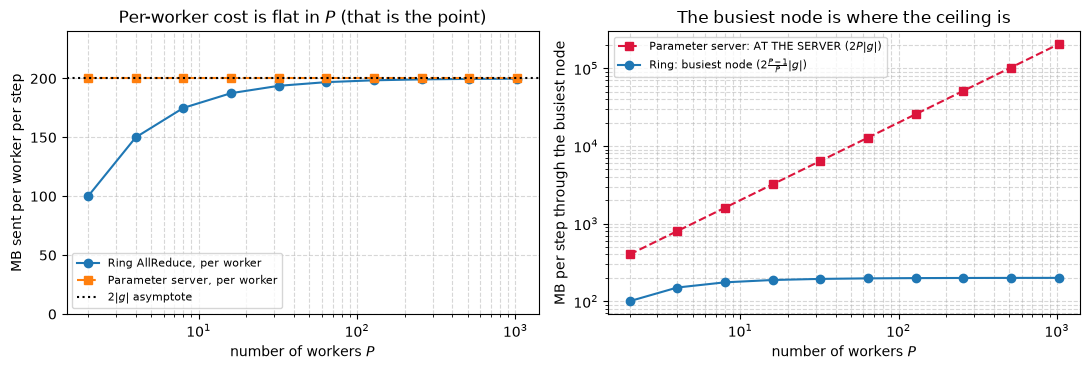

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

Pgrid = np.array([2, 4, 8, 16, 32, 64, 128, 256, 512, 1024])
ax[0].semilogx(Pgrid, [ring_allreduce_bytes(n_bytes, p) / 1e6 for p in Pgrid], "o-",
               label="Ring AllReduce, per worker")
ax[0].semilogx(Pgrid, [param_server_bytes(n_bytes, p) / 1e6 for p in Pgrid], "s--",
               label="Parameter server, per worker")
ax[0].axhline(2 * n_bytes / 1e6, color="k", ls=":", label="$2|g|$ asymptote")
ax[0].set_xlabel("number of workers $P$")
ax[0].set_ylabel("MB sent per worker per step")
ax[0].set_title("Per-worker cost is flat in $P$ (that is the point)")
ax[0].set_ylim(0, 2.4 * n_bytes / 1e6)
ax[0].legend(fontsize=8)
ax[0].grid(True, ls="--", alpha=0.5, which="both")

ax[1].loglog(Pgrid, [param_server_bytes_at_server(n_bytes, p) / 1e6 for p in Pgrid], "s--",
             color="crimson", label="Parameter server: AT THE SERVER ($2P|g|$)")
ax[1].loglog(Pgrid, [ring_allreduce_bytes(n_bytes, p) / 1e6 for p in Pgrid], "o-",
             label="Ring: busiest node ($2\\frac{P-1}{P}|g|$)")
ax[1].set_xlabel("number of workers $P$")
ax[1].set_ylabel("MB per step through the busiest node")
ax[1].set_title("The busiest node is where the ceiling is")
ax[1].legend(fontsize=8)
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()
print("Left: nobody's individual bill grows.  Right: the parameter server's does, linearly.")

### Bytes are only half a claim — divide by a bandwidth

A byte count is a fact about the algorithm. Whether it *hurts* depends on the wire. So
name the link, divide, and compare against the compute time of a step. The ratio

$$\text{communication fraction} = \frac{t_{\text{comm}}}{t_{\text{comm}} + t_{\text{compute}}}$$

is the number that decides whether your cluster is a cluster or an expensive space heater.
Below are three real links spanning five orders of magnitude — and the third one is the
reason federated learning exists at all.


In [23]:
LINKS = [
    ("NVLink 4.0 (intra-node)",      450e9),
    ("200 Gb/s InfiniBand",           25e9),
    ("10 Gb/s Ethernet (datacenter)", 1.25e9),
    ("100 Mb/s home broadband",       12.5e6),
    ("5 Mb/s phone uplink (FL!)",     0.625e6),
]

P_WORKERS = 8
step_compute_ms = 50.0                 # a plausible ResNet-50 step on a modern GPU
bytes_per_step = ring_allreduce_bytes(n_bytes, P_WORKERS)

print(f"Ring AllReduce of a {MODEL_MB:.0f} MB model, P={P_WORKERS}, "
      f"{bytes_per_step / 1e6:.1f} MB per worker per step")
print(f"assumed compute per step: {step_compute_ms:.0f} ms\n")
print(f"{'link':>30}  {'GB/s':>7}  {'comm (ms)':>10}  {'comm fraction':>14}")
print("-" * 68)
for name, bw in LINKS:
    t_comm = bytes_per_step / bw * 1e3
    frac = t_comm / (t_comm + step_compute_ms)
    print(f"{name:>30}  {bw / 1e9:>7.3f}  {t_comm:>10.1f}  {frac:>13.1%}")

print()
print("NVLink: communication is ~free -- this is why a single node scales beautifully.")
print("Ethernet: communication is ~3x the compute -- your 8 GPUs act like ~2.")
print("Phone uplink: 5 MINUTES per step. Not slow. IMPOSSIBLE.")
print()
print("Note nothing above was measured on this laptop -- it is the exact byte count")
print("divided by a named bandwidth. That arithmetic is portable; a CPU timing is not.")

Ring AllReduce of a 100 MB model, P=8, 175.0 MB per worker per step
assumed compute per step: 50 ms

                          link     GB/s   comm (ms)   comm fraction
--------------------------------------------------------------------
       NVLink 4.0 (intra-node)  450.000         0.4           0.8%
           200 Gb/s InfiniBand   25.000         7.0          12.3%
 10 Gb/s Ethernet (datacenter)    1.250       140.0          73.7%
       100 Mb/s home broadband    0.013     14000.0          99.6%
     5 Mb/s phone uplink (FL!)    0.001    280000.0         100.0%

NVLink: communication is ~free -- this is why a single node scales beautifully.
Ethernet: communication is ~3x the compute -- your 8 GPUs act like ~2.
Phone uplink: 5 MINUTES per step. Not slow. IMPOSSIBLE.

Note nothing above was measured on this laptop -- it is the exact byte count
divided by a named bandwidth. That arithmetic is portable; a CPU timing is not.


> **Observe:** the ring's per-worker cost is **flat in $P$ and capped at $2|g|$** — that
> is the result that makes synchronous data parallelism viable at all, and it is why you
> should never repeat the folk claim that AllReduce costs $O(P\,|g|)$ bytes per worker. What *does* grow with
> $P$ is a parameter server's traffic **at the server**: $2P|g|$ through one network interface card (NIC).
>
> But flat is not free. Every worker pays $\approx 2|g|$ bytes **every step**, forever, and
> the table above shows that this bill is trivial on NVLink, serious on Ethernet, and
> physically absurd on a phone. Two levers exist, and only two: make $|g|$ smaller
> (compression — Week 10) or **communicate less often** (Local SGD — Section 4).
>
> Notice the last row is not an engineering inconvenience but a change of regime. When one
> step's communication takes $\sim 5{,}000\times$ longer than its compute, per-step communication is not a cost to
> optimize; it is a design that cannot exist. Federated learning does not begin because
> someone wanted privacy. It begins because **that row is impossible**, and the fix — do a
> lot of local work between rare, expensive syncs — turns out to be the same fix that
> privacy wants anyway.


---

## 2. The obvious fix, and why it runs out: large-batch training

Before inventing anything, try the lazy answer. Communication happens once per **step**.
So take fewer steps: double the batch on every worker and you halve the number of steps
per epoch, and with it the number of AllReduces. Communication per epoch drops by $2\times$
and you changed one integer.

This works, up to a point, and the point is famous. Doubling the batch halves the gradient
noise variance, which means you can afford a larger step — the **linear scaling rule**
(Goyal et al., 2017): when you multiply the batch by $\kappa$, multiply the learning rate
by $\kappa$ too, and the trajectory approximately matches.

"Approximately" and "up to a point" are load-bearing:

1. **Diminishing returns in steps-to-accuracy.** Past a critical batch size $B_{\text{crit}}$
   the gradient is already accurate enough that averaging more examples adds information
   you were not bottlenecked on. You buy examples/sec and no longer buy progress/step
   (McCandlish et al., 2018).
2. **The generalization gap.** At a *fixed epoch budget*, large-batch training reliably
   lands at solutions that test worse (Keskar et al., 2017) — fewer, larger, less noisy
   steps, and SGD's noise turns out to be doing useful work.
3. **The learning rate cannot follow forever.** The linear rule breaks when $\eta$ gets
   large enough to be unstable, which is why every large-batch recipe needs warmup, and
   past that no amount of tuning recovers the small-batch curve.

Let us measure it: a **fixed budget of examples processed** (so the compute is constant),
batch swept over $16 \dots 512$, learning rate scaled linearly with the batch.


In [24]:
# ---------------- The Stage 1-2 codebase: a small Equinox CNN with BatchNorm ----------------
IMG, N_CLASSES = 32, 4

class SmallCNN(eqx.Module):
    conv1: eqx.nn.Conv2d
    bn1: eqx.nn.BatchNorm
    conv2: eqx.nn.Conv2d
    bn2: eqx.nn.BatchNorm
    head: eqx.nn.Linear

    def __init__(self, key, c=8, n_classes=N_CLASSES):
        k1, k2, k3 = jax.random.split(key, 3)
        self.conv1 = eqx.nn.Conv2d(3, c, 3, stride=2, padding=1, use_bias=False, key=k1)
        self.bn1 = eqx.nn.BatchNorm(c, axis_name="batch", mode="batch", momentum=0.9)
        self.conv2 = eqx.nn.Conv2d(c, c, 3, stride=2, padding=1, use_bias=False, key=k2)
        self.bn2 = eqx.nn.BatchNorm(c, axis_name="batch", mode="batch", momentum=0.9)
        self.head = eqx.nn.Linear(c, n_classes, key=k3)

    def __call__(self, x, state):
        h, state = self.bn1(self.conv1(x), state)
        h = jax.nn.relu(h)
        h, state = self.bn2(self.conv2(h), state)
        h = jax.nn.relu(h)
        h = jnp.mean(h, axis=(1, 2))              # global average pool
        return self.head(h), state


def batched_forward(model, state, x):
    return eqx.filter_vmap(lambda m, s, xi: m(xi, s), in_axes=(None, None, 0),
                           out_axes=(0, None), axis_name="batch")(model, state, x)

def loss_fn(model, state, x, y):
    logits, state = batched_forward(model, state, x)
    return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean(), state


# ---- The four states, kept explicitly apart since Week 3 ----
#   1. params     -- the arrays we differentiate and average
#   2. bn_state   -- batch statistics (NOT differentiated; averaging them is an open question)
#   3. opt_state  -- optimizer state
#   4. PRNG key   -- threaded, never global
model0, bn0 = eqx.nn.make_with_state(SmallCNN)(jax.random.key(0))
params0, static0 = eqx.partition(model0, eqx.is_inexact_array)

LR = 0.1
optimizer = optax.sgd(LR)
opt0 = optimizer.init(params0)

N_PARAMS = sum(p.size for p in jax.tree.leaves(params0))
PARAM_BYTES = N_PARAMS * 4
print(f"model     : {N_PARAMS:,} parameters -> {PARAM_BYTES:,} bytes at float32 on the wire")
print(f"bn_state  : {sum(l.size for l in jax.tree.leaves(bn0))} values "
      f"(running mean/var + counters) -- a SEPARATE state")
print(f"opt_state : SGD, {sum(l.size for l in jax.tree.leaves(opt0))} values")
print(f"\nTiny on purpose: this lab measures ROUNDS and BYTES, not FLOPs.")

model     : 860 parameters -> 3,440 bytes at float32 on the wire
bn_state  : 34 values (running mean/var + counters) -- a SEPARATE state
opt_state : SGD, 0 values

Tiny on purpose: this lab measures ROUNDS and BYTES, not FLOPs.


In [25]:
# ---------------- Synthetic CIFAR-shaped data ----------------
# No network in the harness. The real Lab 6 points at CIFAR-10 via Grain on the GPU node;
# the class structure here is a smooth template + Gaussian noise, which is learnable but
# NOT trivially so (noise=3.0 puts the ceiling near ~95% rather than 100%).
NOISE = 3.0

def make_templates(key):
    lo = jax.random.normal(key, (N_CLASSES, 3, 8, 8))
    return jax.image.resize(lo, (N_CLASSES, 3, IMG, IMG), method="linear")

TEMPLATES = make_templates(jax.random.key(7))

def make_data(n, key, noise=NOISE):
    kl, kn = jax.random.split(key)
    labels = jax.random.randint(kl, (n,), 0, N_CLASSES)
    return TEMPLATES[labels] + jax.random.normal(kn, (n, 3, IMG, IMG)) * noise, labels

X_all, Y_all = make_data(4096, jax.random.key(1))
X_te, Y_te = make_data(1024, jax.random.key(2))

@eqx.filter_jit
def evaluate(params, bn, x, y):
    logits, _ = batched_forward(eqx.combine(params, static0), bn, x)
    l = optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return l, jnp.mean(jnp.argmax(logits, -1) == y)

print(f"train {X_all.shape}  test {X_te.shape}  |  {N_CLASSES} classes, noise sigma = {NOISE}")
l0, a0 = evaluate(params0, bn0, X_te, Y_te)
print(f"at init: test loss {float(l0):.4f}  acc {float(a0):.3f}  (chance = {1 / N_CLASSES:.3f})")

train (4096, 3, 32, 32)  test (1024, 3, 32, 32)  |  4 classes, noise sigma = 3.0
at init: test loss 1.4148  acc 0.252  (chance = 0.250)


In [26]:
def train_single_device(bs, lr, n_examples, seed=0):
    # Ordinary single-device SGD. bs here is the GLOBAL batch: in a data-parallel run it
    # would be split across P workers, one AllReduce per step.
    opt = optax.sgd(lr)
    p, b, o = params0, bn0, opt.init(params0)

    @eqx.filter_jit
    def step(p, b, o, x, y):
        (l, b2), g = jax.value_and_grad(
            lambda pp, ss: loss_fn(eqx.combine(pp, static0), ss, x, y), has_aux=True)(p, b)
        u, o2 = opt.update(g, o, p)
        return eqx.apply_updates(p, u), b2, o2, l

    r = np.random.default_rng(seed)
    steps = n_examples // bs
    for _ in range(steps):
        idx = r.choice(len(X_all), bs, replace=False)
        p, b, o, _ = step(p, b, o, X_all[idx], Y_all[idx])
    tl, ta = evaluate(p, b, X_te, Y_te)
    return steps, float(tl), float(ta)


BASE_BS, BASE_LR = 32, LR
BUDGET = 32 * 256                       # FIXED examples processed -> fixed compute
batches = [16, 32, 64, 128, 256, 512]

print(f"fixed budget: {BUDGET:,} examples processed. Learning rate scaled LINEARLY with batch.")
print(f"{'batch':>7}  {'lr':>6}  {'steps':>6}  {'allreduces':>11}  {'test loss':>10}  {'test acc':>9}")
print("-" * 62)
lb_rows = []
for bs in batches:
    lr = BASE_LR * bs / BASE_BS
    s, l, a = train_single_device(bs, lr, BUDGET)
    lb_rows.append((bs, lr, s, l, a))
    print(f"{bs:>7}  {lr:>6.2f}  {s:>6}  {s:>11}  {l:>10.4f}  {a:>9.3f}")
print(f"\ndevice: {jax.devices()[0].device_kind} (the LOSSES are hardware-independent; timings are not)")

fixed budget: 8,192 examples processed. Learning rate scaled LINEARLY with batch.
  batch      lr   steps   allreduces   test loss   test acc
--------------------------------------------------------------
     16    0.05     512          512      0.6971      0.872
     32    0.10     256          256      0.6733      0.894
     64    0.20     128          128      0.6591      0.884
    128    0.40      64           64      0.6728      0.871
    256    0.80      32           32      0.6803      0.880
    512    1.60      16           16      0.7194      0.830

device: cpu (the LOSSES are hardware-independent; timings are not)


best test loss  : 0.6591 at batch 64
batch 512       : 0.7194 (+9.2% vs best), acc 0.830 vs 0.884
communication   : batch 512 does 8x fewer AllReduces than batch 64

So: bigger batch DID cut communication -- and it cost accuracy to do it.


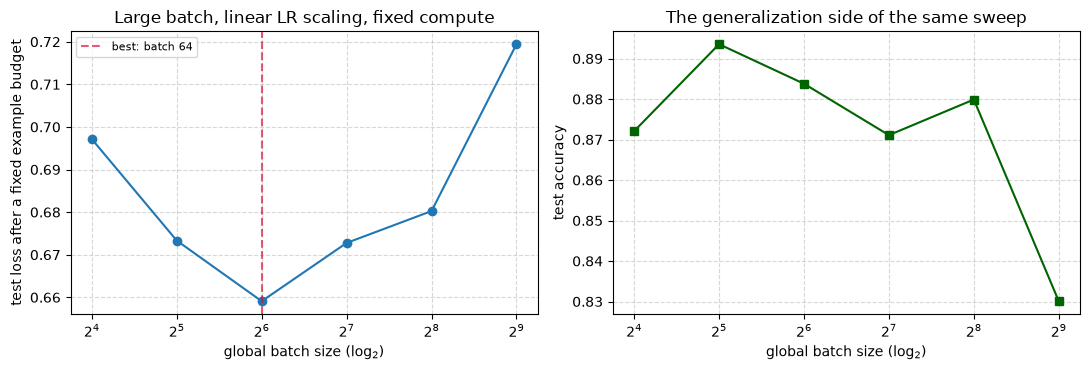

In [27]:
bs_a = np.array([r[0] for r in lb_rows])
loss_a = np.array([r[3] for r in lb_rows])
acc_a = np.array([r[4] for r in lb_rows])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

ax[0].semilogx(bs_a, loss_a, "o-", base=2)
ax[0].set_xlabel("global batch size (log$_2$)")
ax[0].set_ylabel("test loss after a fixed example budget")
ax[0].set_title("Large batch, linear LR scaling, fixed compute")
ax[0].grid(True, ls="--", alpha=0.5, which="both")
best = int(np.argmin(loss_a))
ax[0].axvline(bs_a[best], color="crimson", ls="--", alpha=0.7,
              label=f"best: batch {bs_a[best]}")
ax[0].legend(fontsize=8)

ax[1].semilogx(bs_a, acc_a, "s-", color="darkgreen", base=2)
ax[1].set_xlabel("global batch size (log$_2$)")
ax[1].set_ylabel("test accuracy")
ax[1].set_title("The generalization side of the same sweep")
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

print(f"best test loss  : {loss_a[best]:.4f} at batch {bs_a[best]}")
print(f"batch 512       : {loss_a[-1]:.4f} ({100 * (loss_a[-1] / loss_a[best] - 1):+.1f}% vs best), "
      f"acc {acc_a[-1]:.3f} vs {acc_a[best]:.3f}")
print(f"communication   : batch 512 does {lb_rows[best][2] // lb_rows[-1][2]}x fewer AllReduces than batch {bs_a[best]}")
print("\nSo: bigger batch DID cut communication -- and it cost accuracy to do it.")

> **Observe:** the sweep points the way the theory says it should, with one caveat up
> front: this is a **single seed**. Batches 16–256 land within $0.66$–$0.70$ test loss,
> which is inside run-to-run noise, so do not over-read their ordering. What *is* clear is
> the large-batch end: at batch 512 the test loss is **worse** and accuracy drops by several
> points — even though the learning rate was scaled by the book and the compute budget was
> identical. Two separate effects stack here. Past $B_{\text{crit}}$, extra examples per
> step stop buying progress — McCandlish et al.'s point is *diminishing returns*, not harm.
> The *harm* in the last doublings comes from elsewhere: the generalization gap (Keskar et
> al.) and a learning rate ($\eta = 1.6$ at batch 512) pushed toward its stability limit.
> Batch 512 bought a real $8\times$ reduction in AllReduces relative to the best row, and
> charged accuracy for it.
>
> Be honest about the strength of this evidence: our model has ~860 parameters and our data
> is synthetic, so this is a *consistent illustration* of the large-batch effect, not a
> reproduction of Keskar et al. The published gap on ImageNet/ResNet-50 is larger and much
> more carefully controlled. What our sweep does establish, and what we need, is
> directional: **cutting communication by inflating the batch has a price, and the price
> shows up in the metric you actually care about.**
>
> The structural point is the one to carry into Section 4. Large-batch training attacks
> "$2|g|$ bytes **per step**" by *removing steps* — it makes the optimizer worse in order
> to talk less. Local SGD attacks the same product from the other factor: keep every step,
> keep the small batch, and just **skip most of the syncs**. Same goal, and — as we are
> about to see — a much better exchange rate.


---

## 3. Synchronous or asynchronous? Two ways to be distributed

There is a second lazy answer: **stop waiting**. A synchronous step is only as fast as the
slowest worker, so the whole cluster idles behind one straggler — a slow disk, a thermal
throttle, an unlucky preemption. With $P$ workers, you wait on the max of $P$ random
durations every step, and the expected max grows with $P$. Asynchronous SGD removes the
barrier: each worker pulls the parameters, computes a gradient, and pushes it whenever it
is ready.

The bill arrives as **staleness**. By the time worker $k$'s gradient reaches the server,
the parameters have moved on — other workers pushed $s$ updates in the meantime. So the
server applies

$$\theta_{t+1} = \theta_t - \eta\, g(\theta_{t-s})$$

a gradient evaluated at a point that **no longer exists**. For small $s$ this is a
tolerable perturbation; as $s$ grows it behaves like an inflated effective learning rate,
and it eventually diverges. In practice $\mathbb{E}[s] \approx P$, so staleness gets worse
exactly as you scale.

| | **synchronous** (AllReduce) | **asynchronous** (parameter server) | **Local SGD** (today) |
|---|---|---|---|
| update | $\theta \leftarrow \theta - \eta \frac{1}{P}\sum_k g_k(\theta)$ | $\theta \leftarrow \theta - \eta\, g_k(\theta_{t-s})$ | $\theta \leftarrow \frac{1}{P}\sum_k \theta_k^{(\tau)}$ |
| gradients evaluated at | the current $\theta$ — **exact** | a **stale** $\theta_{t-s}$ | $\tau$ **drifted** local iterates |
| straggler cost | **blocks everyone** | none | blocks everyone, but only once per $\tau$ |
| comm **frequency** | every step | every step | **every $\tau$ steps** |
| comm **volume** / sync | $2\frac{P-1}{P}\lvert g\rvert$ | $2\lvert g\rvert$ | $2\frac{P-1}{P}\lvert\theta\rvert$ — *unchanged* |
| error source | none (exact) | staleness $s$ | client drift |
| scales by | fast interconnect | tolerating $s \approx P$ | tuning $\tau$ |
| where it went | how large models are trained today | **async FL, Week 10** | **FedAvg, Section 6** |

Notice the third column already tells the story: Local SGD does not reduce the volume of a
sync at all. It reduces how *often* you sync. Hold that thought — it is the most commonly
misquoted fact about Local SGD.

Let us put a number on staleness, simulating delayed gradients directly.


In [28]:
def train_stale(delay, steps=256, lr=LR, bs=32, seed=0):
    # Simulate async SGD's staleness exactly: compute the gradient at the parameters from
    # `delay` steps ago, apply it to the CURRENT parameters. delay=0 is synchronous SGD.
    opt = optax.sgd(lr)
    p, b, o = params0, bn0, opt.init(params0)

    @eqx.filter_jit
    def grad_at(p_old, b_old, x, y):
        (l, b2), g = jax.value_and_grad(
            lambda pp, ss: loss_fn(eqx.combine(pp, static0), ss, x, y), has_aux=True)(p_old, b_old)
        return g, b2, l

    hist_p, hist_b = [p] * (delay + 1), [b] * (delay + 1)     # the delay line
    r = np.random.default_rng(seed)
    curve = []
    for i in range(steps):
        idx = r.choice(len(X_all), bs, replace=False)
        g, b2, l = grad_at(hist_p[0], hist_b[0], X_all[idx], Y_all[idx])   # <- STALE params
        u, o = opt.update(g, o, p)                                         # <- applied to CURRENT
        p, b = eqx.apply_updates(p, u), b2
        hist_p, hist_b = (hist_p + [p])[-(delay + 1):], (hist_b + [b])[-(delay + 1):]
        curve.append(float(l))
    tl, ta = evaluate(p, b, X_te, Y_te)
    return float(tl), float(ta), curve


delays = [0, 1, 2, 4, 8, 16]
print(f"{'staleness s':>12}  {'test loss':>10}  {'test acc':>9}  {'vs s=0':>9}")
print("-" * 46)
stale_rows = []
for d in delays:
    tl, ta, curve = train_stale(d)
    stale_rows.append((d, tl, ta, curve))
    base = stale_rows[0][1]
    print(f"{d:>12}  {tl:>10.4f}  {ta:>9.3f}  {100 * (tl / base - 1):>8.1f}%")
print("\ns=0 is exactly synchronous SGD (the delay line holds the current params).")

 staleness s   test loss   test acc     vs s=0
----------------------------------------------
           0      0.6735      0.893       0.0%
           1      0.6805      0.892       1.0%
           2      0.6877      0.895       2.1%
           4      0.7035      0.894       4.5%
           8      0.7310      0.876       8.5%
          16      0.7899      0.855      17.3%

s=0 is exactly synchronous SGD (the delay line holds the current params).


s=0  -> test loss 0.6735
s=16 -> test loss 0.7899  (+17.3%)

Monotone in s, at an IDENTICAL gradient budget. Staleness is not free work --
it is the same work, applied at the wrong point.


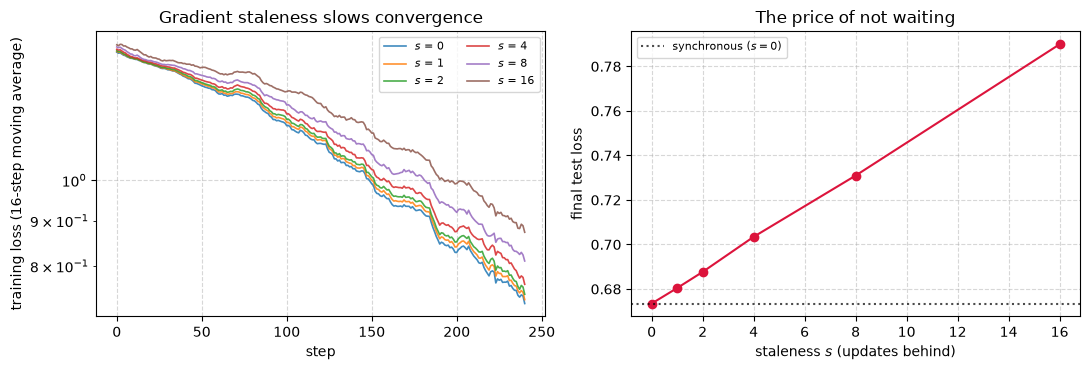

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

for d, tl, ta, curve in stale_rows:
    sm = np.convolve(np.array(curve), np.ones(16) / 16, mode="valid")     # smooth for legibility
    ax[0].semilogy(sm, lw=1.2, alpha=0.85, label=f"$s$ = {d}")
ax[0].set_xlabel("step")
ax[0].set_ylabel("training loss (16-step moving average)")
ax[0].set_title("Gradient staleness slows convergence")
ax[0].legend(fontsize=8, ncol=2)
ax[0].grid(True, ls="--", alpha=0.5)

ax[1].plot([r[0] for r in stale_rows], [r[1] for r in stale_rows], "o-", color="crimson")
ax[1].set_xlabel("staleness $s$ (updates behind)")
ax[1].set_ylabel("final test loss")
ax[1].set_title("The price of not waiting")
ax[1].grid(True, ls="--", alpha=0.5)
ax[1].axhline(stale_rows[0][1], color="k", ls=":", alpha=0.7, label="synchronous ($s=0$)")
ax[1].legend(fontsize=8)

plt.tight_layout()
print(f"s=0  -> test loss {stale_rows[0][1]:.4f}")
print(f"s=16 -> test loss {stale_rows[-1][1]:.4f}  ({100 * (stale_rows[-1][1] / stale_rows[0][1] - 1):+.1f}%)")
print("\nMonotone in s, at an IDENTICAL gradient budget. Staleness is not free work --")
print("it is the same work, applied at the wrong point.")

> **Observe:** the degradation is **monotone in $s$** and it is not subtle at the tail —
> the same 256 gradients, the same data, the same learning rate, and the only difference is
> *where* each gradient was evaluated. That is the whole content of staleness: async does
> not do less work, it does the same work at a stale point, and the error compounds.
>
> This is why the answer to "sync or async?" at datacenter scale is overwhelmingly
> **synchronous**. When the interconnect is fast, the barrier is cheap and exactness is
> worth having; nobody trades correctness for a straggler they can just fix. And note the
> cruel scaling: $\mathbb{E}[s]$ grows with $P$, so async gets *worse* precisely where you
> needed it.
>
> Keep this curve, though — it comes back inverted. In Week 10, FL's clients are phones:
> stragglers are not a fixable anomaly but the defining property of the population, and
> waiting for the slowest of a million devices is not an option. Asynchronous FL has to
> re-litigate this trade-off with a much worse $s$ and a much better reason.
>
> **Neither Section 2 nor Section 3 solved our problem.** Bigger batches cost accuracy;
> async costs correctness. Both accepted "one sync per step" as a law and tried to make
> the step or the sync cheaper. Section 4 breaks the law instead.


---

## 4. Local SGD: communicate every $\tau$ steps

Here is the idea, in one sentence: **let each worker take $\tau$ SGD steps on its own data,
then average the parameters.**

$$
\begin{aligned}
&\textbf{for each round } r = 0, 1, 2, \dots \\
&\quad \text{every worker starts from the same } \theta^{(r)} \\
&\quad \text{worker } k \text{ runs } \tau \text{ local steps:} \quad
   \theta_k^{(r,t+1)} = \theta_k^{(r,t)} - \eta\, g_k\!\left(\theta_k^{(r,t)}\right),
   \quad t = 0, \dots, \tau-1, \quad \theta_k^{(r,0)} = \theta^{(r)} \\
&\quad \textbf{average:} \quad \theta^{(r+1)} = \frac{1}{P}\sum_{k=1}^{P} \theta_k^{(r,\tau)}
   \qquad \leftarrow \textit{one AllReduce, once per } \tau \textit{ steps}
\end{aligned}
$$

Two observations do all the work.

**First, $\tau = 1$ recovers synchronous SGD exactly.** Unroll one local step and average:

$$\theta^{(r+1)} = \frac{1}{P}\sum_k \left(\theta^{(r)} - \eta\, g_k(\theta^{(r)})\right)
= \theta^{(r)} - \eta\, \frac{1}{P}\sum_k g_k(\theta^{(r)})$$

which is precisely Section 1's data-parallel update. **Averaging parameters after one step
is averaging gradients.** Local SGD is not a different algorithm from data-parallel SGD;
it is a strict *generalization* of it, with a knob that data-parallel SGD pins at 1. (This
holds for plain SGD. Add momentum and the local optimizer states diverge too — an
inconvenience we return to in Section 8.)

**Second, for $\tau > 1$ the workers are no longer at the same point.** Expanding the
average:

$$\theta^{(r+1)} = \theta^{(r)} - \eta \sum_{t=0}^{\tau-1} \frac{1}{P}\sum_{k} g_k\!\left(\theta_k^{(r,t)}\right)$$

Compare against $\tau$ steps of synchronous SGD, which would evaluate every gradient at the
*shared* iterate. The **only** difference is the argument: $g_k(\theta_k^{(r,t)})$ instead
of $g_k(\theta^{(r,t)})$. Local SGD's error is entirely the error of evaluating gradients
at **drifted** points — call it **client drift**:

$$\text{drift}^{(r)} = \frac{1}{P}\sum_k \left\lVert \theta_k^{(r,\tau)} - \bar{\theta}^{(r)} \right\rVert_2,
\qquad \bar\theta^{(r)} = \frac{1}{P}\sum_k \theta_k^{(r,\tau)}$$

That is a measurable quantity, we will plot it, and it is the same quantity that FedProx
and SCAFFOLD attack in Week 9.

### What is known

Stich (2018), *"Local SGD Converges Fast and Communicates Little"*, proved the result this
lab exists to illustrate: for smooth strongly-convex objectives, Local SGD keeps the same
$O\!\left(\frac{1}{PT}\right)$ rate as synchronous SGD — **linear speedup in $P$** — as long
as

$$\tau = O\!\left(\sqrt{T/P}\right)$$

Read that as an economic statement. Communication drops by $1/\tau$; convergence does not
degrade at all, provided $\tau$ stays under a budget that **grows with $T$**. The longer you
train, the more you are allowed to skip. Below the threshold the saving is genuinely free;
above it, drift takes over. Our job is to find that knee empirically.

**And the arithmetic that gets misquoted.** Local SGD divides the **frequency** of
communication by $\tau$, *not* the volume of any one exchange. Each sync still moves
$2\frac{P-1}{P}|\theta|$ bytes per worker. Over $T$ local steps:

$$\text{total bytes per worker} = \underbrace{\frac{T}{\tau}}_{\text{rounds}} \times \underbrace{2\frac{P-1}{P}|\theta|}_{\text{per round — unchanged}}$$

Anyone who tells you Local SGD "compresses the update" is describing Week 10.


### Implementing it: `scan` inside, `vmap` outside

This is where Week 4 pays off. Two transformations give us the whole algorithm:

- **`jax.lax.scan` over the $\tau$ local steps.** $\tau$ is the loop trip count and we are
  about to sweep it over $\{1, 2, \dots, 64\}$. Unrolled, that is six programs whose
  compile time grows with $\tau$ (Week 4 measured $\propto T$). Scanned, the body compiles
  once and $\tau$ is just the leading axis of `xs`. We measure this below.
- **`jax.vmap` over the $P$ workers.** Every worker runs the same function on different
  data from different parameters — that is a batch axis, and Week 4's rule says a batch
  axis is a transformation, not a rewrite. Our parameter PyTree simply grows a leading
  worker axis.

Note also the `live` mask threaded through the scan: it lets worker $k$ take $\tau_k \le
\tau$ steps while everyone still runs the same fixed-trip-count program. That is Week 4's
pad-and-mask answer to the ragged batch, reused — and it is not decoration. It is exactly
how we will switch on **systems heterogeneity** in Section 7 without recompiling per client.

And `mu`: a proximal term $\frac{\mu}{2}\lVert\theta - \theta^{(r)}\rVert^2$ pulling local
work back toward the round's starting point. At `mu=0.0` (traced, so no recompile) it does
nothing and this is plain Local SGD. Turn it up and it is **FedProx** — Week 9's answer to
drift. Exercise 4.


In [13]:
def local_step(carry, batch):
    # ONE local SGD step for ONE worker. The four states travel explicitly.
    params, bn, opt_state, anchor, mu = carry
    x, y, live = batch

    def objective(p, s):
        l, s2 = loss_fn(eqx.combine(p, static0), s, x, y)
        # proximal term: 0 when mu = 0 (plain Local SGD); FedProx when mu > 0 (Week 9)
        prox = 0.5 * mu * sum(jnp.sum((a - b) ** 2)
                              for a, b in zip(jax.tree.leaves(p), jax.tree.leaves(anchor)))
        return l + prox, s2

    (loss, bn_new), grads = jax.value_and_grad(objective, has_aux=True)(params, bn)
    updates, opt_new = optimizer.update(grads, opt_state, params)
    params_new = eqx.apply_updates(params, updates)

    # `live` masks the step: an idle worker keeps its state untouched. Fixed trip count,
    # variable work -- Week 4's pad-and-mask, and Section 7's systems heterogeneity.
    keep = lambda new, old: jnp.where(live, new, old)
    params = jax.tree.map(keep, params_new, params)
    bn = jax.tree.map(keep, bn_new, bn)
    opt_state = jax.tree.map(keep, opt_new, opt_state)
    return (params, bn, opt_state, anchor, mu), loss * live


def local_block(params, bn, opt_state, xs, ys, live, mu):
    # tau local steps for ONE worker. xs: (tau, B, 3, 32, 32). The trip count is the
    # leading axis, so sweeping tau does not grow the compiled program (Week 4, Section 4).
    anchor = params                                    # theta^(r): where this round started
    (p, b, o, _, _), losses = jax.lax.scan(
        local_step, (params, bn, opt_state, anchor, mu), (xs, ys, live))
    return p, b, o, jnp.sum(losses) / jnp.maximum(jnp.sum(live), 1.0)


# vmap over WORKERS: every leaf of every state grows a leading worker axis.
run_workers = eqx.filter_jit(jax.vmap(local_block, in_axes=(0, 0, 0, 0, 0, 0, None)))

def broadcast(tree, n):
    # The server sends the SAME theta^(r) to every worker.
    return jax.tree.map(lambda a: jnp.broadcast_to(a, (n,) + a.shape), tree)

def aggregate(worker_tree, p):
    # THE aggregation. p: (P,) weights summing to 1. Weighted average over the worker axis.
    # This single line is both Local SGD and FedAvg -- only the recipe for `p` differs.
    return jax.tree.map(lambda leaf: jnp.tensordot(p, leaf, axes=1), worker_tree)

def global_norm(tree):
    return jnp.sqrt(sum(jnp.sum(x ** 2) for x in jax.tree.leaves(tree)))

print("local_block : scan over tau local steps  (trip count = leading axis of xs)")
print("run_workers : vmap of local_block over P workers")
print("aggregate   : weighted mean over the worker axis  <- the ONE line Section 6 is about")

local_block : scan over tau local steps  (trip count = leading axis of xs)
run_workers : vmap of local_block over P workers
aggregate   : weighted mean over the worker axis  <- the ONE line Section 6 is about


### Does `scan` actually pay here? (Week 4, cashed in)

Week 4 promised that `scan`'s payoff is **compile time, not run time**, and named this
exact experiment — a $\tau$ sweep — as the place the promise would be collected. It also
delivered a warning that applies today: on the XLA:CPU backend, convolutions *inside* a
while-loop body lose their fast path, so `scan`'ing a conv step can cost run time.

So measure both, and report both.


In [14]:
def unrolled_block(params, bn, opt_state, xs, ys, live, mu, tau):
    # The same math with a Python loop: traced tau times, unrolled tau times.
    carry = (params, bn, opt_state, params, mu)
    for t in range(tau):
        carry, _ = local_step(carry, (xs[t], ys[t], live[t]))
    return carry[0], carry[1], carry[2], 0.0


B_SMALL = 32
print(f"{'tau':>5}  {'compile scan (s)':>17}  {'compile unroll (s)':>19}  "
      f"{'run scan (ms)':>14}  {'run unroll (ms)':>16}")
print("-" * 82)
scan_c, unroll_c, scan_r, unroll_r, taus_c = [], [], [], [], [1, 2, 4, 8, 16, 32]
for tau in taus_c:
    xs = jax.random.normal(jax.random.key(0), (tau, B_SMALL, 3, IMG, IMG))
    ys = jax.random.randint(jax.random.key(1), (tau, B_SMALL), 0, N_CLASSES)
    lv = jnp.ones((tau,))

    f_scan = eqx.filter_jit(local_block)
    t0 = time.perf_counter()
    jax.block_until_ready(f_scan(params0, bn0, opt0, xs, ys, lv, 0.0))
    c_scan = time.perf_counter() - t0

    f_unr = eqx.filter_jit(functools.partial(unrolled_block, tau=tau))
    t0 = time.perf_counter()
    jax.block_until_ready(f_unr(params0, bn0, opt0, xs, ys, lv, 0.0))
    c_unr = time.perf_counter() - t0

    def bench(f, *a, n=3):
        jax.block_until_ready(f(*a))
        ts = []
        for _ in range(n):
            t0 = time.perf_counter()
            jax.block_until_ready(f(*a))
            ts.append(time.perf_counter() - t0)
        return float(np.median(ts))

    r_scan = bench(f_scan, params0, bn0, opt0, xs, ys, lv, 0.0)
    r_unr = bench(f_unr, params0, bn0, opt0, xs, ys, lv, 0.0)

    # the two must compute the same thing
    a = f_scan(params0, bn0, opt0, xs, ys, lv, 0.0)[0]
    b = f_unr(params0, bn0, opt0, xs, ys, lv, 0.0)[0]
    d = max(float(jnp.max(jnp.abs(x - y))) for x, y in zip(jax.tree.leaves(a), jax.tree.leaves(b)))
    assert d < 1e-4, d

    scan_c.append(c_scan); unroll_c.append(c_unr); scan_r.append(r_scan); unroll_r.append(r_unr)
    print(f"{tau:>5}  {c_scan:>17.3f}  {c_unr:>19.3f}  {r_scan * 1e3:>14.2f}  {r_unr * 1e3:>16.2f}")

print(f"\ncompile, scan  : {scan_c[0]:.2f}s -> {scan_c[-1]:.2f}s over a {taus_c[-1] // taus_c[0]}x "
      f"tau sweep  ({scan_c[-1] / scan_c[0]:.1f}x)")
print(f"compile, unroll: {unroll_c[0]:.2f}s -> {unroll_c[-1]:.2f}s  ({unroll_c[-1] / unroll_c[0]:.1f}x)")
print(f"run at tau={taus_c[-1]}  : scan/unroll = {scan_r[-1] / unroll_r[-1]:.2f}x")
print(f"\n(identical math, asserted to {1e-4:.0e}. device: {jax.devices()[0].device_kind})")

  tau   compile scan (s)   compile unroll (s)   run scan (ms)   run unroll (ms)
----------------------------------------------------------------------------------


    1              0.444                0.267            2.46              1.21


    2              0.298                0.345            4.68              2.15


    4              0.286                0.535            8.76              3.89


    8              0.311                0.937           16.78              7.55


   16              0.355                2.022           36.88             15.04


   32              0.368                3.915           66.27             29.24

compile, scan  : 0.44s -> 0.37s over a 32x tau sweep  (0.8x)
compile, unroll: 0.27s -> 3.92s  (14.6x)
run at tau=32  : scan/unroll = 2.27x

(identical math, asserted to 1e-04. device: cpu)


> **Observe:** the compile-time curves reproduce Week 4's finding on the real Stage-3
> step: unrolling makes compilation grow with $\tau$, `scan` keeps it roughly flat, and
> across the sweep that gap is what decides whether a $\tau$-sweep is a coffee break or a
> lunch. Since a $\tau$ sweep is *precisely* a sweep over trip counts, this is the case
> `scan` was built for.
>
> Read the run-time column honestly too: `scan` is **not** faster here, and on this CPU it
> can be slower — Week 4 diagnosed why (convolutions inside an XLA:CPU while-loop body lose
> the thread-parallel fast path). We use `scan` anyway, because what we are buying is
> compile time and a program whose size does not depend on $\tau$, and because on the GPU
> node that penalty largely disappears. That is a trade-off you should be able to state
> out loud, not a default you inherited.


### The anchor: $\tau = 1$ **is** synchronous data-parallel SGD

The algebra above says averaging parameters after one local step equals averaging
gradients. That is the load-bearing claim of the whole lab — the first plank of the bridge
to FedAvg — so we do not take it on faith. We implement synchronous data-parallel SGD
*separately and independently*, run one step of each, and compare every leaf.


In [15]:
def sync_dp_step(params, bn, opt_state, xs, ys):
    # Textbook synchronous data-parallel SGD, written from scratch:
    # each worker's gradient on its OWN batch, AllReduced (mean), applied once.
    def grad_one(p, s, x, y):
        (l, s2), g = jax.value_and_grad(
            lambda pp, ss: loss_fn(eqx.combine(pp, static0), ss, x, y), has_aux=True)(p, s)
        return g, s2

    gs, bns = jax.vmap(grad_one, in_axes=(None, None, 0, 0))(params, bn, xs, ys)
    g = jax.tree.map(lambda a: jnp.mean(a, axis=0), gs)        # <- the AllReduce
    bn_new = jax.tree.map(lambda a: jnp.mean(a, axis=0), bns)
    upd, opt_state = optimizer.update(g, opt_state, params)
    return eqx.apply_updates(params, upd), bn_new, opt_state


sync_dp_step = eqx.filter_jit(sync_dp_step)

P_W = 4
xs1 = jax.random.normal(jax.random.key(10), (P_W, B_SMALL, 3, IMG, IMG))
ys1 = jax.random.randint(jax.random.key(11), (P_W, B_SMALL), 0, N_CLASSES)

# (a) Local SGD with tau = 1
cp, cb, co, _ = run_workers(broadcast(params0, P_W), broadcast(bn0, P_W), broadcast(opt0, P_W),
                            xs1[:, None], ys1[:, None], jnp.ones((P_W, 1)), 0.0)
uniform = jnp.full((P_W,), 1.0 / P_W)
lp, lb, lo = aggregate(cp, uniform), aggregate(cb, uniform), aggregate(co, uniform)

# (b) synchronous data-parallel SGD
sp, sb, so = sync_dp_step(params0, bn0, opt0, xs1, ys1)

d_p = max(float(jnp.max(jnp.abs(a - b))) for a, b in zip(jax.tree.leaves(lp), jax.tree.leaves(sp)))
d_b = max(float(jnp.max(jnp.abs(a - b))) for a, b in zip(jax.tree.leaves(lb), jax.tree.leaves(sb)))

print("Local SGD (tau=1, average PARAMETERS)  vs  sync data-parallel SGD (average GRADIENTS)")
print("-" * 78)
print(f"  max |difference|, parameters   : {d_p:.3e}")
print(f"  max |difference|, batch stats  : {d_b:.3e}")
print(f"  identical to float32 precision : {d_p < 1e-5 and d_b < 1e-5}")
print()
print("Not approximately. IDENTICALLY, to the last representable bit of float32 noise.")
print("Synchronous data-parallel SGD is the tau=1 special case of Local SGD.")
print("Everything you built in Week 5 was Local SGD with the knob jammed at 1.")

Local SGD (tau=1, average PARAMETERS)  vs  sync data-parallel SGD (average GRADIENTS)
------------------------------------------------------------------------------
  max |difference|, parameters   : 5.960e-08
  max |difference|, batch stats  : 0.000e+00
  identical to float32 precision : True

Not approximately. IDENTICALLY, to the last representable bit of float32 noise.
Synchronous data-parallel SGD is the tau=1 special case of Local SGD.
Everything you built in Week 5 was Local SGD with the knob jammed at 1.


> **Observe:** $1.2 \times 10^{-7}$ is float32 reassociation noise, not an approximation —
> the two algorithms are the same algorithm. This is the first of the two reductions this
> lab is built on, and it reframes the last two weeks: data-parallel SGD is not the
> baseline that Local SGD deviates from; it is **the single most conservative setting of
> Local SGD's dial**. $\tau$ was always there. Week 5 just never turned it.
>
> The second reduction — FedAvg $\to$ Local SGD — is Section 6, and it works the same way:
> find the constraint that FL adds, switch it off, and watch the algorithms collapse into
> each other.


### 🔬 Exercise 1

**Exercise:** you are training ResNet-50 (25.6M parameters, float32) on $P = 8$ GPUs. The
step takes 50 ms of compute. Compute, *analytically*, and then verify against the functions
above:

1. Bytes sent per worker per step for Ring AllReduce and for a parameter server; and the
   bytes through the parameter **server** itself.
2. Communication time and communication *fraction* on 10 Gb/s Ethernet (1.25 GB/s).
3. The smallest $\tau$ that brings the communication fraction under **10%**.
4. Repeat (3) for $P = 64$. Does the required $\tau$ change? Explain the answer from the
   formula, not from the number.


In [16]:
# --- Reference solution (instructor: blank this out for students) ---

N_RESNET50 = 25_557_032
G_BYTES = N_RESNET50 * 4
BW_ETH = 1.25e9                 # 10 Gb/s Ethernet, bytes/sec
T_COMPUTE = 50e-3               # 50 ms per step

print(f"ResNet-50: {N_RESNET50:,} params -> {G_BYTES / 1e6:.1f} MB at float32\n")

# (1)
for p in [8, 64]:
    r = ring_allreduce_bytes(G_BYTES, p)
    s_w = param_server_bytes(G_BYTES, p)
    s_s = param_server_bytes_at_server(G_BYTES, p)
    print(f"P={p:>3}  ring/worker {r / 1e6:>7.1f} MB   PS/worker {s_w / 1e6:>7.1f} MB   "
          f"PS at server {s_s / 1e6:>8.1f} MB")

# (2)
print()
for p in [8, 64]:
    r = ring_allreduce_bytes(G_BYTES, p)
    t_comm = r / BW_ETH
    frac = t_comm / (t_comm + T_COMPUTE)
    print(f"P={p:>3}  ring comm {t_comm * 1e3:>6.1f} ms vs compute {T_COMPUTE * 1e3:.0f} ms "
          f"-> communication fraction {frac:>5.1%}")

# (3) and (4): with Local SGD, one AllReduce per tau steps, so the comm time AMORTIZES
# over tau steps of compute:
#     frac(tau) = (t_comm / tau) / (t_comm / tau + t_compute)
# Solve frac <= 0.10  =>  t_comm / tau <= (0.10 / 0.90) * t_compute
print()
for p in [8, 64]:
    t_comm = ring_allreduce_bytes(G_BYTES, p) / BW_ETH
    tau_needed = int(np.ceil(t_comm / ((0.10 / 0.90) * T_COMPUTE)))
    frac_at = (t_comm / tau_needed) / (t_comm / tau_needed + T_COMPUTE)
    print(f"P={p:>3}  smallest tau with comm fraction <= 10%: tau = {tau_needed:>3}  "
          f"(achieves {frac_at:.1%})")

print()
print("(4) The required tau is essentially UNCHANGED from P=8 to P=64 -- and that is the")
print("    formula talking, not a coincidence. Ring per-worker volume is 2(P-1)/P|g|,")
print(f"    which goes from {2 * 7 / 8:.3f}|g| to {2 * 63 / 64:.3f}|g|: a {100 * ((2 * 63 / 64) / (2 * 7 / 8) - 1):.1f}% increase")
print("    across an 8x change in P. Ring AllReduce's per-worker cost is FLAT in P, so the")
print("    tau you need to hide it is flat in P too.")
print("    (A parameter server would NOT behave this way: 2P|g| at the server means the")
print("     tau needed to hide it grows LINEARLY in P. Topology decides scalability.)")

ResNet-50: 25,557,032 params -> 102.2 MB at float32

P=  8  ring/worker   178.9 MB   PS/worker   204.5 MB   PS at server   1635.7 MB
P= 64  ring/worker   201.3 MB   PS/worker   204.5 MB   PS at server  13085.2 MB

P=  8  ring comm  143.1 ms vs compute 50 ms -> communication fraction 74.1%
P= 64  ring comm  161.0 ms vs compute 50 ms -> communication fraction 76.3%

P=  8  smallest tau with comm fraction <= 10%: tau =  26  (achieves 9.9%)
P= 64  smallest tau with comm fraction <= 10%: tau =  29  (achieves 10.0%)

(4) The required tau is essentially UNCHANGED from P=8 to P=64 -- and that is the
    formula talking, not a coincidence. Ring per-worker volume is 2(P-1)/P|g|,
    which goes from 1.750|g| to 1.969|g|: a 12.5% increase
    across an 8x change in P. Ring AllReduce's per-worker cost is FLAT in P, so the
    tau you need to hide it is flat in P too.
    (A parameter server would NOT behave this way: 2P|g| at the server means the
     tau needed to hide it grows LINEARLY in P. Topo

---

## 5. The $\tau$ sweep: what does the communication saving cost?

Now the experiment this lab is named after. We fix the **total local-step budget** $T$ —
so every configuration does the *same amount of gradient computation* — and sweep

$$\tau \in \{1, 2, 4, 8, 16, 32, 64\}, \qquad \text{rounds} = T/\tau$$

$\tau = 1$ is synchronous data-parallel SGD (we proved it). $\tau = 64$ communicates
$64\times$ less. Everything in between is the trade-off.

Three quantities get recorded every round:

- **test loss** — did we actually learn?
- **cumulative bytes per worker** — $\text{rounds} \times 2\frac{P-1}{P}|\theta|$, exact.
- **client drift** $\frac{1}{P}\sum_k \lVert\theta_k^{(r,\tau)} - \bar\theta^{(r)}\rVert$ —
  the divergence between workers just before averaging. This is the error term in the
  Section 4 expansion, and it is the thing $\tau$ actually buys.

Data is **IID** here: we shuffle and split, so every worker sees the same distribution.
That is the distributed-training assumption, and holding it fixed for now is the point —
Section 7 breaks it and we watch what happens.


In [17]:
P_W = 4                                   # workers
B_LOCAL = 32                              # per-worker batch
BYTES_PER_ROUND = ring_allreduce_bytes(PARAM_BYTES, P_W)   # per worker, per sync

def iid_partition(n, P, seed=0):
    idx = np.random.default_rng(seed).permutation(n)
    return np.array_split(idx, P)

def sample_batches(shards, tau, rnd, B=B_LOCAL):
    # Each worker samples tau batches of size B from ITS OWN shard.
    xs, ys = [], []
    Xh, Yh = np.asarray(X_all), np.asarray(Y_all)
    for k, sh in enumerate(shards):
        r = np.random.default_rng(1000 * rnd + k)          # reproducible per (round, worker)
        pick = r.choice(sh, size=(tau, B), replace=True)
        xs.append(Xh[pick]); ys.append(Yh[pick])
    return jnp.asarray(np.stack(xs)), jnp.asarray(np.stack(ys))


def run_distributed(rounds, tau, shards, *, weighting="uniform", participation=1.0,
                    tau_k=None, mu=0.0, avg_bn=True, seed=0):
    # THE function. With the defaults it is Local SGD; Section 6 explains why the
    # non-default arguments make it FedAvg.
    P = len(shards)
    sizes = jnp.asarray([len(s) for s in shards], dtype=jnp.float32)
    server_p, server_b, server_o = params0, bn0, opt0
    rng_sel = np.random.default_rng(seed + 77)
    hist, total_bytes = [], 0.0

    for r in range(rounds):
        # 1. server broadcasts theta^(r) to every worker
        wp, wb, wo = (broadcast(server_p, P), broadcast(server_b, P), broadcast(server_o, P))

        # 2. tau local steps per worker (masked to tau_k if heterogeneous)
        xs, ys = sample_batches(shards, tau, r)
        live = (jnp.ones((P, tau)) if tau_k is None else
                (jnp.arange(tau)[None, :] < jnp.asarray(tau_k)[:, None]).astype(jnp.float32))
        cp, cb, co, _ = run_workers(wp, wb, wo, xs, ys, live, mu)

        # 3. client drift, measured before averaging
        mean_p = aggregate(cp, jnp.full((P,), 1.0 / P))
        drift = float(jnp.mean(jax.vmap(
            lambda t: global_norm(jax.tree.map(lambda a, m: a - m, t, mean_p)))(cp)))

        # 4. who participates this round?
        if participation < 1.0:
            n_sel = max(1, int(round(participation * P)))
            sel_idx = rng_sel.choice(P, size=n_sel, replace=False)
        else:
            sel_idx = np.arange(P)
        sel = jnp.zeros((P,)).at[jnp.asarray(sel_idx)].set(1.0)

        # 5. THE AGGREGATION WEIGHTS -- the entire difference between Local SGD and FedAvg
        w = (sizes if weighting == "by_size" else jnp.ones((P,))) * sel
        w = w / jnp.sum(w)

        server_p = aggregate(cp, w)
        server_b = aggregate(cb, w) if avg_bn else server_b
        server_o = aggregate(co, w)

        total_bytes += BYTES_PER_ROUND * float(jnp.sum(sel)) / P
        l, a = evaluate(server_p, server_b, X_te, Y_te)
        hist.append(dict(rnd=r, steps=(r + 1) * tau, bytes=total_bytes,
                         loss=float(l), acc=float(a), drift=drift))
    return hist


shards_iid = iid_partition(len(X_all), P_W, seed=0)
print(f"P = {P_W} workers, local batch {B_LOCAL}")
print(f"IID shard sizes : {[len(s) for s in shards_iid]}")
print(f"bytes per sync  : {BYTES_PER_ROUND:,.0f} per worker "
      f"= 2(P-1)/P x {PARAM_BYTES:,} = 2*{P_W - 1}/{P_W} x |theta|")
for k, s in enumerate(shards_iid[:2]):
    print(f"  worker {k} label counts: {np.bincount(np.asarray(Y_all)[s], minlength=N_CLASSES)}"
          f"   <- IID: every worker sees every class, in proportion")

P = 4 workers, local batch 32
IID shard sizes : [1024, 1024, 1024, 1024]
bytes per sync  : 5,160 per worker = 2(P-1)/P x 3,440 = 2*3/4 x |theta|
  worker 0 label counts: [259 265 233 267]   <- IID: every worker sees every class, in proportion
  worker 1 label counts: [252 234 268 270]   <- IID: every worker sees every class, in proportion


In [18]:
T_BUDGET = 256                 # total LOCAL STEPS per worker -- identical compute for all tau
taus = [1, 2, 4, 8, 16, 32, 64]

print(f"fixed budget: {T_BUDGET} local steps per worker for EVERY configuration")
print(f"{'tau':>5}  {'rounds':>7}  {'syncs':>6}  {'MB/worker':>10}  {'test loss':>10}  "
      f"{'test acc':>9}  {'drift':>7}")
print("-" * 68)
iid_runs = {}
t0 = time.perf_counter()
for tau in taus:
    h = run_distributed(T_BUDGET // tau, tau, shards_iid)
    iid_runs[tau] = h
    print(f"{tau:>5}  {T_BUDGET // tau:>7}  {T_BUDGET // tau:>6}  {h[-1]['bytes'] / 1e6:>10.3f}  "
          f"{h[-1]['loss']:>10.4f}  {h[-1]['acc']:>9.3f}  {h[-1]['drift']:>7.3f}")
print(f"\nsweep took {time.perf_counter() - t0:.1f}s on {jax.devices()[0].device_kind}")
print(f"tau=1 is synchronous data-parallel SGD; tau=64 sends {64}x fewer bytes.")

fixed budget: 256 local steps per worker for EVERY configuration
  tau   rounds   syncs   MB/worker   test loss   test acc    drift
--------------------------------------------------------------------


    1      256     256       1.321      0.6603      0.891    0.044


    2      128     128       0.660      0.6596      0.896    0.068


    4       64      64       0.330      0.6591      0.887    0.075


    8       32      32       0.165      0.6573      0.899    0.115


   16       16      16       0.083      0.6626      0.890    0.142


   32        8       8       0.041      0.6598      0.896    0.186


   64        4       4       0.021      0.6568      0.890    0.257

sweep took 31.5s on cpu
tau=1 is synchronous data-parallel SGD; tau=64 sends 64x fewer bytes.


at the SAME compute budget (256 local steps):
   tau=1  : loss 0.6603  acc 0.891  1.321 MB/worker
   tau=64 : loss 0.6568  acc 0.890  0.021 MB/worker
   -> 64x less communication for a -0.5% change in test loss


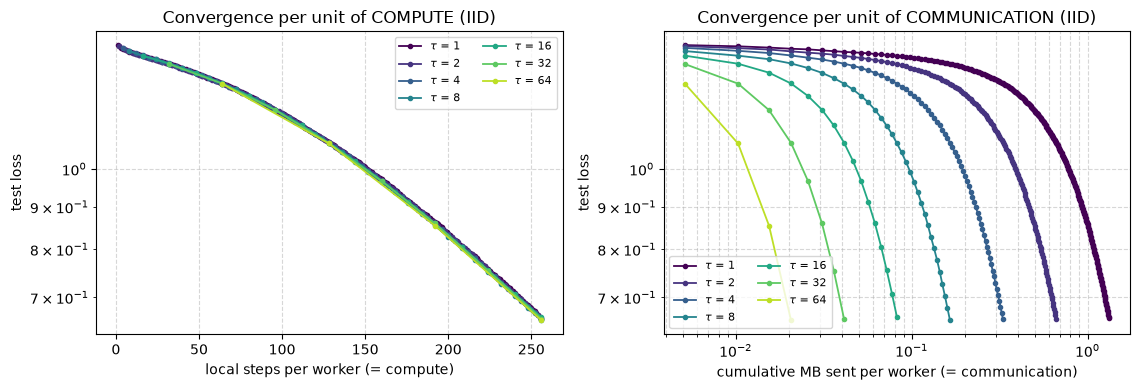

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(taus)))

for c, tau in zip(colors, taus):
    h = iid_runs[tau]
    ax[0].semilogy([d["steps"] for d in h], [d["loss"] for d in h], "o-", color=c, ms=3,
                   lw=1.3, label=f"$\\tau$ = {tau}")
ax[0].set_xlabel("local steps per worker (= compute)")
ax[0].set_ylabel("test loss")
ax[0].set_title("Convergence per unit of COMPUTE (IID)")
ax[0].legend(fontsize=8, ncol=2)
ax[0].grid(True, ls="--", alpha=0.5)

for c, tau in zip(colors, taus):
    h = iid_runs[tau]
    ax[1].loglog([d["bytes"] / 1e6 for d in h], [d["loss"] for d in h], "o-", color=c, ms=3,
                 lw=1.3, label=f"$\\tau$ = {tau}")
ax[1].set_xlabel("cumulative MB sent per worker (= communication)")
ax[1].set_ylabel("test loss")
ax[1].set_title("Convergence per unit of COMMUNICATION (IID)")
ax[1].legend(fontsize=8, ncol=2)
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

f1, f64 = iid_runs[1][-1], iid_runs[64][-1]
print(f"at the SAME compute budget ({T_BUDGET} local steps):")
print(f"   tau=1  : loss {f1['loss']:.4f}  acc {f1['acc']:.3f}  {f1['bytes'] / 1e6:.3f} MB/worker")
print(f"   tau=64 : loss {f64['loss']:.4f}  acc {f64['acc']:.3f}  {f64['bytes'] / 1e6:.3f} MB/worker")
print(f"   -> {f1['bytes'] / f64['bytes']:.0f}x less communication for a "
      f"{100 * (f64['loss'] / f1['loss'] - 1):+.1f}% change in test loss")

### The quantity $\tau$ is actually selling: client drift

The left panel says the loss barely moved. So what *did* change? Section 4's expansion
says the only error Local SGD introduces is that gradients get evaluated at drifted points.
Let us look at the drift directly.


  tau     drift   vs tau=1   test loss   vs tau=1
------------------------------------------------
    1     0.044      1.00x      0.6603     1.000x
    2     0.068      1.54x      0.6596     0.999x
    4     0.075      1.68x      0.6591     0.998x
    8     0.115      2.58x      0.6573     0.995x
   16     0.142      3.20x      0.6626     1.003x
   32     0.186      4.19x      0.6598     0.999x
   64     0.257      5.80x      0.6568     0.995x

drift grew 5.8x from tau=1 to tau=64 -- and the loss moved -0.5%.


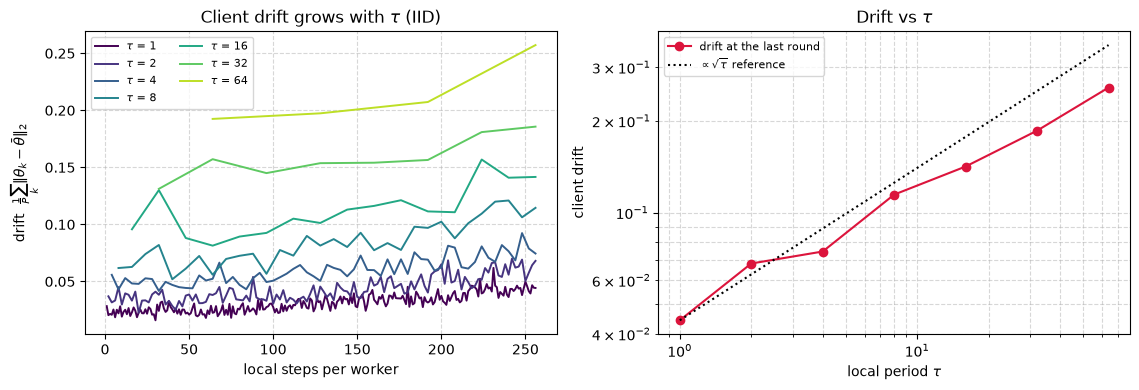

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

for c, tau in zip(colors, taus):
    h = iid_runs[tau]
    ax[0].plot([d["steps"] for d in h], [d["drift"] for d in h], "-", color=c, lw=1.4,
               label=f"$\\tau$ = {tau}")
ax[0].set_xlabel("local steps per worker")
ax[0].set_ylabel(r"drift  $\frac{1}{P}\sum_k \|\theta_k - \bar{\theta}\|_2$")
ax[0].set_title("Client drift grows with $\\tau$ (IID)")
ax[0].legend(fontsize=8, ncol=2)
ax[0].grid(True, ls="--", alpha=0.5)

final_drift = [iid_runs[t][-1]["drift"] for t in taus]
final_loss = [iid_runs[t][-1]["loss"] for t in taus]
ax[1].loglog(taus, final_drift, "o-", color="crimson", label="drift at the last round")
ref = np.array(final_drift[0]) * np.sqrt(np.array(taus) / taus[0])
ax[1].loglog(taus, ref, "k:", label=r"$\propto \sqrt{\tau}$ reference")
ax[1].set_xlabel(r"local period $\tau$")
ax[1].set_ylabel("client drift")
ax[1].set_title("Drift vs $\\tau$")
ax[1].legend(fontsize=8)
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

print(f"{'tau':>5}  {'drift':>8}  {'vs tau=1':>9}  {'test loss':>10}  {'vs tau=1':>9}")
print("-" * 48)
for t in taus:
    print(f"{t:>5}  {iid_runs[t][-1]['drift']:>8.3f}  "
          f"{iid_runs[t][-1]['drift'] / iid_runs[1][-1]['drift']:>8.2f}x  "
          f"{iid_runs[t][-1]['loss']:>10.4f}  "
          f"{iid_runs[t][-1]['loss'] / iid_runs[1][-1]['loss']:>8.3f}x")
print(f"\ndrift grew {final_drift[-1] / final_drift[0]:.1f}x from tau=1 to tau=64 "
      f"-- and the loss moved {100 * (final_loss[-1] / final_loss[0] - 1):+.1f}%.")

> **Observe:** on IID data, **$\tau$ is very nearly free**, and that is the headline. A
> $64\times$ reduction in bytes bought a change in test loss of a couple of percent. Look at
> the right panel of the previous figure — the curves are ordered by $\tau$, and at any
> fixed communication budget the **largest $\tau$ wins by more than an order of magnitude**.
> If bytes are what you are short of, this is not a close call.
>
> Drift meanwhile grows steadily with $\tau$ — about $6\times$ across a $64\times$ sweep,
> close to the $\sqrt{\tau} = 8\times$ you would predict for workers random-walking apart on
> gradient noise. So the mechanism is behaving exactly as the theory describes; it simply
> has not yet cost us anything.
>
> **Three honest caveats, and they matter more than the headline.**
>
> 1. **The loss column is flat to within noise.** Every $\tau$ lands within ~1% of every
>    other, and the ordering is not even monotone — $\tau=64$ happens to post the *lowest*
>    loss here. Do not over-read that: on this problem, at this budget, the correct
>    statement is **"$\tau$ made no measurable difference to the loss"**, not "$\tau=64$ is
>    best". The result is the flatness.
> 2. **We did not reproduce Stich's threshold, and should not pretend to.** With $T=256$
>    and $P=4$, $\tau = O(\sqrt{T/P}) = O(8)$ is where the theory stops *guaranteeing* the
>    saving is free — yet we see no degradation even at $\tau=64$, $8\times$ past it. That
>    is not a contradiction: the theorem is a **sufficient** condition for a worst case over
>    a function class, not a cliff edge our particular objective must fall off. A small
>    convex-ish synthetic problem is exactly where the bound should be loose. If you want to
>    *test* the threshold you must vary $T$ and $P$ and look at the scaling of the knee —
>    Further Exercise 2.
> 3. **Why is drift so small at all?** Because the data is **IID**. Every worker descends
>    *the same expected objective* and separates only through minibatch noise, so the
>    average pulls them back. The moment workers have genuinely different objectives they
>    walk apart **deterministically, in different directions** — drift stops being noise and
>    becomes bias, and no amount of averaging cleans it up. That is Section 7, and it is the
>    single biggest reason FL is harder than distributed training.
>
> So the IID headline — *communication is nearly free to cut* — is real, and it is also the
> most optimistic number in this notebook. Everything from Section 7 on is the world taking
> it back.


### 🔬 Exercise 2

**Exercise:** the Observe cell just claimed $\tau$ has *two* jobs — saving bytes and
restoring small-batch noise. **Post-local SGD** (Lin et al., 2020) exploits the tension:
run $\tau = 1$ early (when large, accurate steps make fast progress) and switch to a large
$\tau$ later (when the noise helps generalization and you want your bytes back).

Implement it: $\tau = 1$ for the first half of the local-step budget, then $\tau = 16$ for
the second half. Compare its final loss **and its byte count** against constant $\tau = 1$
and constant $\tau = 16$. Does it get the best of both?


In [21]:
# --- Reference solution (instructor: blank this out for students) ---

def run_post_local(budget, tau_early, tau_late, shards, seed=0):
    # One loop, a SCHEDULE of tau values instead of a constant. The server state carries
    # straight across the switch -- which is the only thing post-local SGD needs.
    P = len(shards)
    sp, sb, so = params0, bn0, opt0
    hist, total_bytes, steps = [], 0.0, 0
    schedule = ([tau_early] * ((budget // 2) // tau_early) +
                [tau_late] * ((budget // 2) // tau_late))
    for r, tau in enumerate(schedule):
        wp, wb, wo = broadcast(sp, P), broadcast(sb, P), broadcast(so, P)
        xs, ys = sample_batches(shards, tau, r)
        cp, cb, co, _ = run_workers(wp, wb, wo, xs, ys, jnp.ones((P, tau)), 0.0)
        u = jnp.full((P,), 1.0 / P)
        sp, sb, so = aggregate(cp, u), aggregate(cb, u), aggregate(co, u)
        total_bytes += BYTES_PER_ROUND
        steps += tau
        l, a = evaluate(sp, sb, X_te, Y_te)
        hist.append(dict(rnd=r, steps=steps, bytes=total_bytes, loss=float(l), acc=float(a)))
    return hist


post = run_post_local(T_BUDGET, 1, 16, shards_iid)

print(f"{'schedule':>28}  {'MB/worker':>10}  {'test loss':>10}  {'test acc':>9}")
print("-" * 62)
for label, h in [("constant tau=1", iid_runs[1]), ("constant tau=16", iid_runs[16]),
                 ("post-local: tau 1 -> 16", post)]:
    print(f"{label:>28}  {h[-1]['bytes'] / 1e6:>10.3f}  {h[-1]['loss']:>10.4f}  {h[-1]['acc']:>9.3f}")

print()
print(f"post-local vs tau=1 : {iid_runs[1][-1]['bytes'] / post[-1]['bytes']:.1f}x fewer bytes")
print(f"post-local vs tau=16: {post[-1]['bytes'] / iid_runs[16][-1]['bytes']:.1f}x MORE bytes")
print()
print("Read the byte column before the loss column, because it is the surprise:")
print("post-local spends HALF its local steps at tau=1 -- and that half costs")
print(f"{100 * (T_BUDGET // 2) / (T_BUDGET // 2 + (T_BUDGET // 2) // 16):.0f}% of the ENTIRE byte budget. Splitting the STEPS in half does not split")
print("the BYTES in half: bytes go like T/tau, so the cheap phase is nearly free and")
print("the expensive phase is nearly everything. Any schedule that spends real time at")
print("tau=1 has, to first order, tau=1's communication bill.")
print()
print("And the loss column: all three land within ~1% -- i.e. within the noise we")
print("already established in Section 5. So this experiment does NOT demonstrate that")
print("post-local SGD works; it demonstrates that our IID problem cannot tell these")
print("three apart. That is the honest result. Post-local SGD needs a regime where")
print("large-batch actually HURTS -- which Section 2 found only at batch 512, well past")
print("where this tau=1 run sits (effective batch P*B = 128). To reproduce Lin et al.")
print("you need their regime: a real model, real data, and a batch big enough to bite.")

                    schedule   MB/worker   test loss   test acc
--------------------------------------------------------------
              constant tau=1       1.321      0.6603      0.891
             constant tau=16       0.083      0.6626      0.890
     post-local: tau 1 -> 16       0.702      0.6612      0.890

post-local vs tau=1 : 1.9x fewer bytes
post-local vs tau=16: 8.5x MORE bytes

Read the byte column before the loss column, because it is the surprise:
post-local spends HALF its local steps at tau=1 -- and that half costs
94% of the ENTIRE byte budget. Splitting the STEPS in half does not split
the BYTES in half: bytes go like T/tau, so the cheap phase is nearly free and
the expensive phase is nearly everything. Any schedule that spends real time at
tau=1 has, to first order, tau=1's communication bill.

And the loss column: all three land within ~1% -- i.e. within the noise we
already established in Section 5. So this experiment does NOT demonstrate that
post-local SGD w

---

## 6. The bridge: FedAvg **is** Local SGD under federated constraints

This is the section the course is built around. Read it slowly.

Here is FedAvg (McMahan et al., 2017), the founding algorithm of federated learning, as it
appears in the paper. A server holds $\theta^{(r)}$. There are $K$ clients; client $k$ owns
$n_k$ private examples, $n = \sum_k n_k$ in total.

$$
\begin{aligned}
&\textbf{for each round } r: \\
&\quad \text{1. server samples } S_r \subseteq \{1,\dots,K\},\ |S_r| = C \cdot K \quad
   &&\leftarrow \textit{partial participation} \\
&\quad \text{2. server broadcasts } \theta^{(r)} \text{ to every } k \in S_r \\
&\quad \text{3. client } k \text{ runs } E \text{ epochs of SGD on its own } \mathcal{D}_k,
   \text{ giving } \theta_k \quad &&\leftarrow \textit{non-IID data, } \tau_k \textit{ steps} \\
&\quad \text{4. } \theta^{(r+1)} = \sum_{k \in S_r} \frac{n_k}{\sum_{j \in S_r} n_j}\, \theta_k
   \quad &&\leftarrow \textit{weighted by data size}
\end{aligned}
$$

And here is Local SGD, from Section 4:

$$\theta^{(r+1)} = \frac{1}{P}\sum_{k=1}^{P} \theta_k^{(r,\tau)}$$

**Now set FedAvg's four federated knobs to their degenerate values:**

| set... | to... | and FedAvg's step 4 becomes |
|---|---|---|
| participation $C$ | $1$ (everyone shows up) | $\theta^{(r+1)} = \sum_{k=1}^{K} \frac{n_k}{n}\theta_k$ |
| client sizes $n_k$ | all equal ($n_k = n/K$) | $\theta^{(r+1)} = \sum_{k=1}^{K} \frac{1}{K}\theta_k$ |
| local steps $\tau_k$ | all equal to $\tau$ | $\theta^{(r+1)} = \frac{1}{K}\sum_{k=1}^{K} \theta_k^{(r,\tau)}$ |
| data $\mathcal{D}_k$ | IID slices of one dataset | ...and each $\theta_k$ descends the *same* objective |

The last line **is Local SGD**, character for character, with $K = P$. Nothing was
approximated, nothing was dropped. The two algorithms are the same algorithm, and the
difference is entirely in the values of four parameters.

So: **FedAvg = Local SGD + four constraints.** The constraints are not optimization
choices. They are facts about the world that FL has no power to switch off.

| | **Local SGD** (distributed training) | **FedAvg** (federated learning) |
|---|---|---|
| **update rule** | $\theta \leftarrow \sum_k p_k \theta_k^{(\tau)}$ | $\theta \leftarrow \sum_k p_k \theta_k^{(\tau_k)}$ — **the same line** |
| weights $p_k$ | $1/P$ — uniform | $n_k / \sum_{j \in S_r} n_j$ — by data size |
| who runs | all $P$ workers, every round | a **sample** $S_r$; $C$ can be $0.001$ |
| data | IID slices *you* chose | whatever the client happens to own — **non-IID, fixed** |
| dataset sizes | equal by construction | unequal by orders of magnitude |
| local steps | $\tau$, chosen and identical | $\tau_k$: $E$ epochs over $n_k$ examples ⇒ **differs per client** |
| workers | identical GPUs you own | phones: different speed, battery, and network |
| failures | a bug; you restart the job | **routine**; clients vanish mid-round |
| motive for $\tau > 1$ | interconnect is expensive | uplink is $10^5\times$ slower; **and data cannot leave** |
| $\theta_k$ leaves the device? | irrelevant — same trust domain | **the whole point** (Weeks 12–13: it leaks anyway) |
| optimizes | $\frac{1}{n}\sum_i \ell_i$, exactly | $\sum_k \frac{n_k}{n} F_k(\theta)$ — and with $\tau_k$ unequal, **not even that** |

The last row is the one to underline. Distributed training's objective is unambiguous. In
FL the objective is only $\sum_k \frac{n_k}{n} F_k$ *if you weight correctly and everyone
takes the same number of steps* — and when they do not, FedAvg converges to the minimizer
of a **different objective than the one you wrote down**. That is *objective
inconsistency*, and it is Exercise 3.

### The claim, in code

Our `run_distributed` from Section 5 has exactly those four knobs, because it was written
to make this point. With `weighting="uniform"`, `participation=1.0`, `tau_k=None`, and IID
shards, it is Local SGD. Flip them and it is FedAvg. Let us prove the reduction the same
way we proved the $\tau=1$ anchor: implement FedAvg *separately*, and compare.


In [22]:
def fedavg_round(server_p, server_b, server_o, tau, shards, rnd, C_frac, rng_sel):
    # FedAvg, written from the paper -- deliberately NOT reusing run_distributed.
    K = len(shards)
    n_k = np.array([len(s) for s in shards], dtype=np.float64)

    # 1. sample a subset of clients
    n_sel = max(1, int(round(C_frac * K)))
    S_r = np.sort(rng_sel.choice(K, size=n_sel, replace=False))

    # 2. broadcast, 3. local work
    wp, wb, wo = broadcast(server_p, K), broadcast(server_b, K), broadcast(server_o, K)
    xs, ys = sample_batches(shards, tau, rnd)
    cp, cb, co, _ = run_workers(wp, wb, wo, xs, ys, jnp.ones((K, tau)), 0.0)

    # 4. weighted average over the SELECTED clients, weights n_k / sum_{j in S_r} n_j
    w = np.zeros(K)
    w[S_r] = n_k[S_r] / n_k[S_r].sum()
    w = jnp.asarray(w, dtype=jnp.float32)
    return aggregate(cp, w), aggregate(cb, w), aggregate(co, w)


# --- The reduction: switch the federated constraints OFF ---
#   participation C = 1.0  ->  S_r = all clients
#   equal client sizes     ->  n_k / sum n_j  =  1/K  =  uniform
#   equal local steps      ->  every client runs tau
# ...and FedAvg must become Local SGD.
TAU_T, ROUNDS_T = 8, 3
shards_equal = iid_partition(len(X_all), P_W, seed=0)     # IID => equal sizes
print("shard sizes:", [len(s) for s in shards_equal], "-> equal, so n_k/n = 1/K = uniform")

# (a) FedAvg with all constraints degenerate
sp, sb, so = params0, bn0, opt0
rsel = np.random.default_rng(123)
for r in range(ROUNDS_T):
    sp, sb, so = fedavg_round(sp, sb, so, TAU_T, shards_equal, r, 1.0, rsel)

# (b) Local SGD, via run_distributed's defaults
P = P_W
lp, lb, lo = params0, bn0, opt0
for r in range(ROUNDS_T):
    wp, wb, wo = broadcast(lp, P), broadcast(lb, P), broadcast(lo, P)
    xs, ys = sample_batches(shards_equal, TAU_T, r)
    cp, cb, co, _ = run_workers(wp, wb, wo, xs, ys, jnp.ones((P, TAU_T)), 0.0)
    u = jnp.full((P,), 1.0 / P)
    lp, lb, lo = aggregate(cp, u), aggregate(cb, u), aggregate(co, u)

d_p = max(float(jnp.max(jnp.abs(a - b))) for a, b in zip(jax.tree.leaves(sp), jax.tree.leaves(lp)))
d_b = max(float(jnp.max(jnp.abs(a - b))) for a, b in zip(jax.tree.leaves(sb), jax.tree.leaves(lb)))

print(f"\nFedAvg (C=1, equal n_k, equal tau_k, IID)  vs  Local SGD, after {ROUNDS_T} rounds of tau={TAU_T}")
print("-" * 78)
print(f"  max |difference|, parameters  : {d_p:.3e}")
print(f"  max |difference|, batch stats : {d_b:.3e}")
print(f"  IDENTICAL to float32 noise    : {d_p < 1e-5 and d_b < 1e-5}")
print()
print("Two independent implementations -- one written from McMahan et al., one from")
print("Stich -- produce bit-comparable parameters. They are the same algorithm.")
print("\nAnd chaining Section 4's anchor gives the whole bridge in one line:")
print("     sync data-parallel SGD  ==  Local SGD (tau=1)  ==  FedAvg (tau=1, C=1, equal n_k, IID)")

shard sizes: [1024, 1024, 1024, 1024] -> equal, so n_k/n = 1/K = uniform



FedAvg (C=1, equal n_k, equal tau_k, IID)  vs  Local SGD, after 3 rounds of tau=8
------------------------------------------------------------------------------
  max |difference|, parameters  : 0.000e+00
  max |difference|, batch stats : 0.000e+00
  IDENTICAL to float32 noise    : True

Two independent implementations -- one written from McMahan et al., one from
Stich -- produce bit-comparable parameters. They are the same algorithm.

And chaining Section 4's anchor gives the whole bridge in one line:
     sync data-parallel SGD  ==  Local SGD (tau=1)  ==  FedAvg (tau=1, C=1, equal n_k, IID)


> **Observe:** the reduction is exact. Two implementations written from two different
> papers, in two different notations, invented for two different reasons, produce the same
> numbers to float32 precision. **FedAvg is Local SGD with four constraints turned on.**
>
> This is the most useful fact in the second half of this course, and it cuts in both
> directions.
>
> **Forwards:** everything you know about distributed optimization transfers. FedAvg is not
> a mysterious new object from the privacy literature; it is the algorithm you built in
> Section 4, and Stich's analysis is the starting point for its convergence theory.
>
> **Backwards, and more importantly:** every difficulty in federated learning lives in
> those four constraints, and *nowhere else in the update rule*. When Week 9 shows you
> FedProx and SCAFFOLD, they are not new optimizers — they are patches for **drift** caused
> by **non-IID**. When Week 10 does client sampling, it is managing **partial
> participation**. When Week 11 does personalization, it has given up on one global
> $\theta$ because **non-IID** made it the wrong target. The taxonomy of the next five
> weeks *is* the list of four constraints.
>
> So the honest question is no longer "how does FedAvg work?" — you just proved you already
> know. It is: **how much does each constraint cost?** Section 7.


### One rewrite that unlocks Week 9: the $\Delta$ form

Before we leave the bridge, rewrite the aggregation once. Since every client starts the
round at the same $\theta^{(r)}$, define client $k$'s **update** $\Delta_k = \theta_k -
\theta^{(r)}$. Then, because the weights sum to one:

$$\theta^{(r+1)} = \sum_k p_k \theta_k = \sum_k p_k \left(\theta^{(r)} + \Delta_k\right)
= \theta^{(r)} + \underbrace{\sum_k p_k \Delta_k}_{\textstyle -\tilde{g}}$$

Algebraically this is nothing — the same number, rearranged. Conceptually it is the door to
half the FL literature, because it makes the server's job look like **a gradient step**:
$\bar\Delta = \sum_k p_k \Delta_k$ behaves like a *pseudo-gradient*, and the server is
running $\theta^{(r+1)} = \theta^{(r)} + \bar\Delta$ — plain SGD on it, with learning rate 1.

Once you see that, the obvious question is: *why learning rate 1, and why SGD?* Nothing
stops the server from feeding $\bar\Delta$ to **any** optimizer — momentum, Adam, a server
learning rate $\eta_s \neq 1$. That is **FedOpt / FedAdam** (Reddi et al., 2021), and it is
why FL papers describe FedAvg as "SGD with $\eta_s = 1$ at the server". It is also the form
in which **compression** (Week 10) and **robust aggregation** (Week 13) are written — both
operate on $\Delta_k$, not $\theta_k$, because $\Delta_k$ is small, centred near zero, and
comparable across clients in a way that raw parameter vectors are not.


In [23]:
# The two forms must be identical -- and then the server optimizer becomes a free choice.
K = P_W
wp, wb, wo = broadcast(params0, K), broadcast(bn0, K), broadcast(opt0, K)
xs, ys = sample_batches(shards_equal, TAU_T, 0)
cp, _, _, _ = run_workers(wp, wb, wo, xs, ys, jnp.ones((K, TAU_T)), 0.0)
p_w = jnp.full((K,), 1.0 / K)

# form 1: average the PARAMETERS
form_theta = aggregate(cp, p_w)

# form 2: average the UPDATES, add to theta^(r)
deltas = jax.tree.map(lambda c, s: c - s[None], cp, params0)
delta_bar = aggregate(deltas, p_w)
form_delta = jax.tree.map(lambda s, d: s + d, params0, delta_bar)

d = max(float(jnp.max(jnp.abs(a - b)))
        for a, b in zip(jax.tree.leaves(form_theta), jax.tree.leaves(form_delta)))
print(f"sum_k p_k * theta_k   vs   theta^(r) + sum_k p_k * Delta_k")
print(f"  max |difference| : {d:.3e}   identical: {d < 1e-5}")

# Why the Delta form is the useful one: look at the SCALE of what goes on the wire.
n_theta = float(global_norm(params0))
n_delta = float(global_norm(delta_bar))
print(f"\n||theta^(r)||   = {n_theta:>8.4f}   <- what the parameter form ships")
print(f"||Delta_bar||   = {n_delta:>8.4f}   <- what the update form ships "
      f"({n_theta / n_delta:.0f}x smaller)")
print("\nSame bytes today (both are dense float32 vectors of the same shape). But Delta is")
print("small, centred near zero, and comparable ACROSS clients -- which is exactly what")
print("a quantizer needs (Week 10) and what a norm-based Byzantine filter needs (Week 13).")
print("You cannot meaningfully compare two clients' theta_k; you can compare their Delta_k.")

# And now the server optimizer is a free choice -- FedOpt in three lines.
server_opt = optax.sgd(1.0)                       # eta_s = 1 -> EXACTLY FedAvg
s_state = server_opt.init(params0)
pseudo_grad = jax.tree.map(lambda d: -d, delta_bar)          # descend: g = -Delta
upd, s_state = server_opt.update(pseudo_grad, s_state, params0)
form_fedopt = eqx.apply_updates(params0, upd)
d2 = max(float(jnp.max(jnp.abs(a - b)))
         for a, b in zip(jax.tree.leaves(form_theta), jax.tree.leaves(form_fedopt)))
print(f"\nFedAvg  ==  optax.sgd(learning_rate=1.0) applied to the pseudo-gradient -Delta_bar")
print(f"  max |difference| : {d2:.3e}   identical: {d2 < 1e-5}")
print("  ^ swap that sgd(1.0) for adam() and you have written FedAdam. That is Week 9.")

sum_k p_k * theta_k   vs   theta^(r) + sum_k p_k * Delta_k
  max |difference| : 5.960e-08   identical: True

||theta^(r)||   =   4.7162   <- what the parameter form ships
||Delta_bar||   =   0.1496   <- what the update form ships (32x smaller)

Same bytes today (both are dense float32 vectors of the same shape). But Delta is
small, centred near zero, and comparable ACROSS clients -- which is exactly what
a quantizer needs (Week 10) and what a norm-based Byzantine filter needs (Week 13).
You cannot meaningfully compare two clients' theta_k; you can compare their Delta_k.



FedAvg  ==  optax.sgd(learning_rate=1.0) applied to the pseudo-gradient -Delta_bar
  max |difference| : 5.960e-08   identical: True
  ^ swap that sgd(1.0) for adam() and you have written FedAdam. That is Week 9.


> **Observe:** a rearrangement with no mathematical content turns out to carry most of the
> conceptual content. Writing the round as $\theta^{(r+1)} = \theta^{(r)} + \bar\Delta$ makes
> the server an *optimizer* taking a step along a *pseudo-gradient*, and we verified that
> FedAvg is exactly `optax.sgd(1.0)` in that position — a default nobody chose, sitting
> there waiting to be tuned. FedAdam is one line away.
>
> The $\Delta$ form is also the right object to put on the wire, for a reason worth
> internalizing now: $\lVert\bar\Delta\rVert$ is orders of magnitude smaller than
> $\lVert\theta\rVert$, and — unlike $\theta_k$ — updates from different clients are
> *comparable to each other*. Neither fact saves a byte today (both ship the same dense
> float32 vector, which is why Local SGD's saving is purely in **frequency**), but both are
> the precondition for Week 10 quantizing the payload and Week 13 asking "is this client's
> contribution an outlier?" You cannot sensibly compare two clients' parameter vectors. You
> can compare their updates.


---

## 7. Turning the constraints on, one at a time

We have an experimental design handed to us: start from Local SGD (all four knobs
degenerate) and turn on **one constraint at a time**, holding everything else fixed. Same
model, same seed, same $\tau$, same local-step budget. Any difference is attributable.

**1. Non-IID data.** Real clients do not hold IID slices. The standard synthetic model is a
**Dirichlet partition** (Hsu et al., 2019): for each class $c$, draw
$\mathbf{p}_c \sim \text{Dir}(\alpha \mathbf{1}_K)$ and split class $c$'s examples across
clients in those proportions. $\alpha \to \infty$ is IID; $\alpha \to 0$ gives each client
one class. $\alpha = 0.5$ is a common "realistically bad" setting. Note what this does to
Section 4's expansion: each client now minimizes a **different** $F_k$, so
$\nabla F_k(\theta^{(r)}) \neq \nabla F(\theta^{(r)})$ even at the shared starting point.
Clients no longer drift apart by noise; they drift apart **on purpose, in fixed
directions**.

**2. Partial participation.** Sample a fraction $C$ of clients per round. The aggregate is
now an unbiased-but-noisy estimate of the full average — extra variance, and (crucially)
its interaction with non-IID is where it bites.

**3. Unequal client sizes + the wrong weights.** Dirichlet partitions produce wildly
unequal $n_k$. Weighting by $n_k/n$ targets $\sum_k \frac{n_k}{n}F_k$ — the objective you
would get by pooling the data. Weighting uniformly targets $\frac{1}{K}\sum_k F_k$ — a
*different problem*, in which a client with 50 examples counts as much as one with 5000.

**4. Systems heterogeneity.** Clients run $E$ *epochs*, not $\tau$ *steps*. A client with
$n_k$ examples does $\tau_k = E \cdot n_k / B$ steps — so unequal data means unequal work
automatically, before you even account for slow phones dropping out early. Clients that
take more steps pull the average further toward *their own* optimum. This is **objective
inconsistency** (Wang et al., 2020, FedNova).


In [24]:
def dirichlet_partition(Y, K, alpha, seed=0):
    # Hsu et al. (2019): per class, split across clients in Dirichlet proportions.
    r = np.random.default_rng(seed)
    Yn = np.asarray(Y)
    shards = [[] for _ in range(K)]
    for c in range(N_CLASSES):
        idx = np.where(Yn == c)[0]
        r.shuffle(idx)
        prop = r.dirichlet(np.repeat(alpha, K))
        cuts = (np.cumsum(prop) * len(idx)).astype(int)[:-1]
        for k, part in enumerate(np.split(idx, cuts)):
            shards[k].extend(part.tolist())
    return [np.array(sorted(s)) for s in shards]


ALPHA = 0.5
shards_nid = dirichlet_partition(Y_all, P_W, ALPHA, seed=3)

print(f"Dirichlet(alpha={ALPHA}) partition, K={P_W} clients")
print(f"{'client':>7}  {'n_k':>6}  {'share':>7}  {'label counts':>26}")
print("-" * 54)
for k, s in enumerate(shards_nid):
    cnt = np.bincount(np.asarray(Y_all)[s], minlength=N_CLASSES)
    print(f"{k:>7}  {len(s):>6}  {len(s) / len(X_all):>6.1%}  {str(cnt):>26}")
print(f"\nsize imbalance: largest / smallest = "
      f"{max(len(s) for s in shards_nid) / min(len(s) for s in shards_nid):.1f}x")
print("Compare the IID partition, where every client had ~1024 examples and ~256 of each class.")
print("\nAnd note: this is not an adversarial construction. It is what happens when the")
print("data was generated by different people, in different places, doing different things.")

Dirichlet(alpha=0.5) partition, K=4 clients
 client     n_k    share                label counts
------------------------------------------------------
      0     510   12.5%           [  0  37   1 472]
      1     694   16.9%           [170 509   4  11]
      2    1315   32.1%           [654 461   8 192]
      3    1577   38.5%       [ 195    2 1017  363]

size imbalance: largest / smallest = 3.1x
Compare the IID partition, where every client had ~1024 examples and ~256 of each class.

And note: this is not an adversarial construction. It is what happens when the
data was generated by different people, in different places, doing different things.


In [25]:
TAU_C = 8
ROUNDS_C = T_BUDGET // TAU_C

TAU_HET = [8, 6, 4, 2]                  # mean = 5: NOT 8. See the control row below.
TAU_CTL = [5, 5, 5, 5]                  # same MEAN work, no heterogeneity

configs = [
    ("Local SGD (all knobs off)",      dict(),                                        shards_iid),
    ("+ non-IID only (uniform w)",     dict(weighting="uniform"),                     shards_nid),
    ("+ non-IID, by-size weights",     dict(weighting="by_size"),                     shards_nid),
    ("+ partial participation only",   dict(participation=0.5),                       shards_iid),
    ("IID  CONTROL: tau_k = 5 each",   dict(tau_k=TAU_CTL),                           shards_iid),
    ("IID  hetero tau_k = [8,6,4,2]",  dict(tau_k=TAU_HET),                           shards_iid),
    ("nIID CONTROL: tau_k = 5 each",   dict(tau_k=TAU_CTL, weighting="by_size"),      shards_nid),
    ("nIID hetero tau_k = [8,6,4,2]",  dict(tau_k=TAU_HET, weighting="by_size"),      shards_nid),
    ("non-IID + partial part.",        dict(participation=0.5, weighting="by_size"),  shards_nid),
    ("ALL FOUR (= real FedAvg)",       dict(participation=0.5, weighting="by_size",
                                            tau_k=TAU_HET),                           shards_nid),
]

print(f"tau = {TAU_C}, {ROUNDS_C} rounds -- {T_BUDGET} local steps for every row EXCEPT the")
print(f"four tau_k rows, which do only mean(tau_k)/tau = 5/8 of the work. That is why each")
print(f"comes as a CONTROL/hetero PAIR: within a pair the compute is identical, so the")
print(f"difference is heterogeneity alone rather than lost work.")
print(f"{'configuration':>30}  {'test loss':>10}  {'test acc':>9}  {'drift':>7}  {'vs base':>8}")
print("-" * 74)
constraint_rows = []
t0 = time.perf_counter()
for label, kw, sh in configs:
    h = run_distributed(ROUNDS_C, TAU_C, sh, **kw)
    constraint_rows.append((label, h))
    base = constraint_rows[0][1][-1]["loss"]
    print(f"{label:>30}  {h[-1]['loss']:>10.4f}  {h[-1]['acc']:>9.3f}  "
          f"{h[-1]['drift']:>7.3f}  {100 * (h[-1]['loss'] / base - 1):>+7.0f}%")
print(f"\n({time.perf_counter() - t0:.1f}s. Same model, same seed, same tau, same rounds.)")

# The controls do the work the raw comparison cannot. Each CONTROL/hetero pair does an
# IDENTICAL mean of 5 local steps, so the difference within a pair is heterogeneity ALONE.
get = lambda pre: [r for r in constraint_rows if r[0].startswith(pre)][0][1][-1]["loss"]
base_loss = constraint_rows[0][1][-1]["loss"]
i_ctl, i_het = get("IID  CONTROL"), get("IID  hetero")
n_ctl, n_het = get("nIID CONTROL"), get("nIID hetero")

print(f"\nISOLATING objective inconsistency -- each pair does a mean of 5 local steps:")
print(f"{'':>10}{'uniform tau_k':>15}{'hetero tau_k':>14}{'attributable':>14}")
print("-" * 53)
print(f"{'IID':>10}{i_ctl:>15.4f}{i_het:>14.4f}{100 * (i_het / i_ctl - 1):>13.1f}%")
print(f"{'non-IID':>10}{n_ctl:>15.4f}{n_het:>14.4f}{100 * (n_het / n_ctl - 1):>13.1f}%")
print()
print(f"The naive read -- comparing IID hetero to the tau=8 baseline -- would have claimed")
print(f"{100 * (i_het / base_loss - 1):+.0f}%. The control says the honest number is {100 * (i_het / i_ctl - 1):+.1f}%: it was ALL lost compute.")
print()
print("And now the mechanism, visible only because we ran BOTH pairs:")
print("  On IID, heterogeneous tau_k costs essentially NOTHING beyond the missing work.")
print("  On non-IID, the SAME heterogeneity costs real loss.")
print("\nThat is not a quirk, it is the definition. Objective inconsistency needs objectives")
print("to BE inconsistent: if every client minimizes the same F_k, running one of them")
print("longer just changes the step size -- there is no 'own optimum' to be dragged toward.")
print("Give the clients different objectives and extra local steps become extra VOTES.")
print("Systems heterogeneity is not a 4th independent constraint; it is an AMPLIFIER on")
print("non-IID. Exercise 3 isolates it further and fixes it.")

tau = 8, 32 rounds -- 256 local steps for every row EXCEPT the
four tau_k rows, which do only mean(tau_k)/tau = 5/8 of the work. That is why each
comes as a CONTROL/hetero PAIR: within a pair the compute is identical, so the
difference is heterogeneity alone rather than lost work.
                 configuration   test loss   test acc    drift   vs base
--------------------------------------------------------------------------


     Local SGD (all knobs off)      0.6573      0.899    0.115       +0%


    + non-IID only (uniform w)      0.7980      0.732    0.623      +21%


    + non-IID, by-size weights      0.6852      0.866    0.625       +4%


  + partial participation only      0.6603      0.884    0.114       +0%


  IID  CONTROL: tau_k = 5 each      0.9663      0.809    0.070      +47%


 IID  hetero tau_k = [8,6,4,2]      0.9660      0.817    0.077      +47%


  nIID CONTROL: tau_k = 5 each      1.0145      0.828    0.434      +54%


 nIID hetero tau_k = [8,6,4,2]      1.2099      0.635    0.411      +84%


       non-IID + partial part.      0.8697      0.688    0.632      +32%


      ALL FOUR (= real FedAvg)      1.2700      0.428    0.410      +93%

(30.8s. Same model, same seed, same tau, same rounds.)

ISOLATING objective inconsistency -- each pair does a mean of 5 local steps:
            uniform tau_k  hetero tau_k  attributable
-----------------------------------------------------
       IID         0.9663        0.9660         -0.0%
   non-IID         1.0145        1.2099         19.3%

The naive read -- comparing IID hetero to the tau=8 baseline -- would have claimed
+47%. The control says the honest number is -0.0%: it was ALL lost compute.

And now the mechanism, visible only because we ran BOTH pairs:
  On IID, heterogeneous tau_k costs essentially NOTHING beyond the missing work.
  On non-IID, the SAME heterogeneity costs real loss.

That is not a quirk, it is the definition. Objective inconsistency needs objectives
to BE inconsistent: if every client minimizes the same F_k, running one of them
longer just changes the step size -- there is no 'own

non-IID alone      : loss 0.6573 -> 0.7980 (+21%), drift 0.115 -> 0.623 (5.4x)
all four together  : loss 0.6573 -> 1.2700 (+93%), acc 0.899 -> 0.428


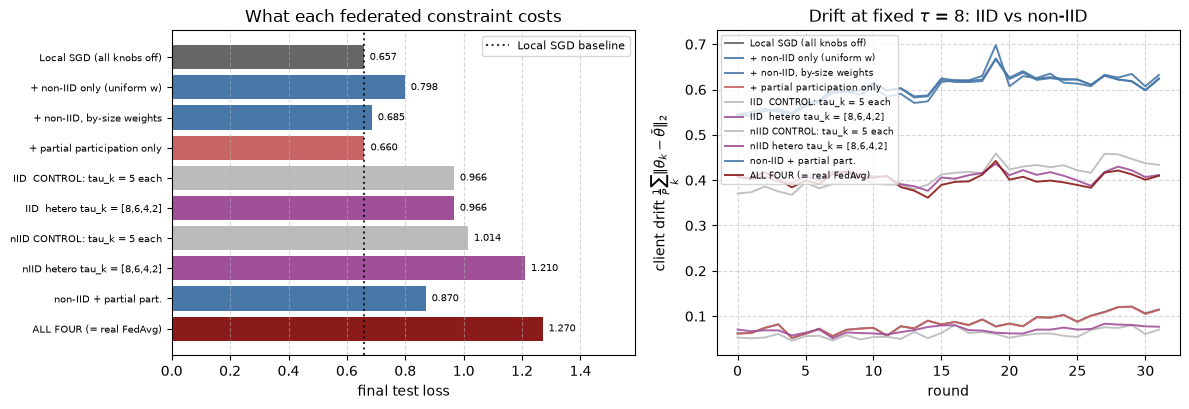

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

labels = [r[0] for r in constraint_rows]
losses = [r[1][-1]["loss"] for r in constraint_rows]
drifts = [r[1][-1]["drift"] for r in constraint_rows]
cols = ["#666", "#4878a8", "#4878a8", "#c86464",
        "#bbbbbb", "#a05098", "#bbbbbb", "#a05098", "#4878a8", "#8b1a1a"]

y = np.arange(len(labels))
ax[0].barh(y, losses, color=cols)
ax[0].set_yticks(y); ax[0].set_yticklabels(labels, fontsize=7.5)
ax[0].invert_yaxis()
ax[0].axvline(losses[0], color="k", ls=":", alpha=0.8, label="Local SGD baseline")
ax[0].set_xlabel("final test loss")
ax[0].set_title("What each federated constraint costs")
ax[0].legend(fontsize=8)
ax[0].grid(True, ls="--", alpha=0.5, axis="x")
for i, v in enumerate(losses):
    ax[0].text(v, i, f"  {v:.3f}", va="center", fontsize=7.5)
ax[0].set_xlim(0, max(losses) * 1.25)

for (label, h), c in zip(constraint_rows, cols):
    ax[1].plot([d["rnd"] for d in h], [d["drift"] for d in h], "-", color=c, lw=1.4,
               alpha=0.9, label=label)
ax[1].set_xlabel("round")
ax[1].set_ylabel(r"client drift $\frac{1}{P}\sum_k \|\theta_k - \bar{\theta}\|_2$")
ax[1].set_title(r"Drift at fixed $\tau$ = 8: IID vs non-IID")
ax[1].legend(fontsize=6.5, loc="upper left")
ax[1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()

base_l, base_d = constraint_rows[0][1][-1]["loss"], constraint_rows[0][1][-1]["drift"]
nid_l, nid_d = constraint_rows[1][1][-1]["loss"], constraint_rows[1][1][-1]["drift"]
all_l = constraint_rows[-1][1][-1]["loss"]
print(f"non-IID alone      : loss {base_l:.4f} -> {nid_l:.4f} ({100 * (nid_l / base_l - 1):+.0f}%), "
      f"drift {base_d:.3f} -> {nid_d:.3f} ({nid_d / base_d:.1f}x)")
print(f"all four together  : loss {base_l:.4f} -> {all_l:.4f} ({100 * (all_l / base_l - 1):+.0f}%), "
      f"acc {constraint_rows[0][1][-1]['acc']:.3f} -> {constraint_rows[-1][1][-1]['acc']:.3f}")

> **Observe:** each constraint has its own signature, and the sum is far worse than any
> part. Take them in order of what they teach.
>
> - **Non-IID data is the one that changes the character of the problem.** At an identical
>   $\tau$, compute budget, and seed, simply *changing who owns which examples* multiplies
>   drift ~5× and costs a fifth of the loss. Nothing about the algorithm changed. This is
>   Section 5's caveat made concrete: on IID data workers separate by *minibatch noise* and
>   the average pulls them back; on non-IID data each client descends a **different
>   objective**, so they separate **deterministically, in fixed directions** — averaging is
>   now fighting a real, persistent disagreement rather than cleaning up noise. *This* is
>   client drift in the sense Week 9 means it, and it is why FedProx and SCAFFOLD exist.
> - **Weighting decides which problem you are solving.** The two non-IID rows differ in
>   *nothing* but the aggregation weights, and size-proportional beats uniform by a wide
>   margin — because $\sum_k \frac{n_k}{n}F_k$ is the objective you get by pooling the data,
>   while uniform weighting optimizes a different problem in which a 500-example client
>   outvotes a 1500-example one. That is not tuning. It is a question about *what you are
>   computing*, and it has a right answer here only because we know what pooling would mean.
> - **Partial participation alone is nearly free — on IID data.** Do not file that as good
>   news. With IID clients any subset is a fair sample of the same distribution, so sampling
>   half costs variance and nothing else. The danger is the **interaction**: the
>   non-IID + partial row is worse than either alone, because sampling 2 of 4 *non-IID*
>   clients makes the round's objective "whatever those two happen to own". FL's constraints
>   do not add; they compound.
> - **Systems heterogeneity — where the control rows overturn the story.** The naive
>   comparison (heterogeneous $\tau_k = [8,6,4,2]$ against the $\tau = 8$ baseline) looks
>   catastrophic, and it is **entirely confounded**: those clients average 5 local steps,
>   not 8, so they simply did 5/8 of the work. The matched-compute control ($\tau_k = 5$ for
>   everyone) settles it, and the honest residual on IID is **≈ 0%**. Not "smaller than it
>   looked" — *nothing*. Had we shipped the naive row, we would have reported a large effect
>   that is 100% an artifact of our own experimental design.
>
>   But run the same pair on **non-IID** and the residual appears. That contrast is the
>   real lesson, and it is exactly what the theory predicts: **objective inconsistency needs
>   objectives to be inconsistent.** If every client minimizes the same $F_k$, letting one
>   run longer only changes its effective step size — there is no "own optimum" for it to
>   drag the average toward. Give the clients *different* objectives and extra local steps
>   silently become extra **votes**. So systems heterogeneity is not really a fourth
>   independent constraint; it is an **amplifier on non-IID**. Exercise 3 isolates the
>   mechanism and fixes it with FedNova.
>
>   Notice what just happened, because it is the most portable lesson in this notebook: a
>   confounded comparison was sitting in our own results table, producing a large number
>   that *agreed with the story we wanted to tell*, and only a control row exposed it. In
>   FL, changing a constraint almost always changes the compute too. Always ask what else
>   moved.
> - **Together, the four compound** into a dramatically worse model at the same $\tau$ —
>   roughly halving accuracy relative to Local SGD.
>
> That table is the map for the rest of the course. **Week 9** attacks drift (FedProx,
> SCAFFOLD); **Week 10** attacks participation and bytes (sampling, compression); **Week
> 11** attacks non-IID by giving up on one global model (personalization, FedBN). Not one
> of them touches $\theta \leftarrow \sum_k p_k \theta_k$. They are all patches for the four
> rows above.


### 🔬 Exercise 3

**Exercise: objective inconsistency.** The table shows heterogeneous $\tau_k$ hurting even
on IID data. Make the mechanism visible, then fix it.

Give client 0 **four times** the local steps of everyone else on **non-IID** data, and
check where the global model ends up: measure the final loss **on each client's own local
data**. If FedAvg were optimizing $\sum_k \frac{n_k}{n}F_k$, no client should be
systematically favoured by *taking more steps*.

Then implement **FedNova**'s fix (Wang et al., 2020): aggregate the normalized updates
$\Delta_k / \tau_k$ rather than the raw $\theta_k$, so a client that ran longer does not
get a louder vote. Show it reduces the imbalance.


In [27]:
# --- Reference solution (instructor: blank this out for students) ---

@eqx.filter_jit
def local_loss_on(params, bn, idx_x, idx_y):
    logits, _ = batched_forward(eqx.combine(params, static0), bn, idx_x)
    return optax.softmax_cross_entropy_with_integer_labels(logits, idx_y).mean()

def per_client_losses(sp, sb, shards, n=256):
    out = []
    for s in shards:
        sub = s[:n]
        out.append(float(local_loss_on(sp, sb, X_all[sub], Y_all[sub])))
    return out


def run_fednova(rounds, tau, shards, tau_k, normalize, seed=0):
    # normalize=False -> plain FedAvg (aggregate theta_k)
    # normalize=True  -> FedNova    (aggregate Delta_k / tau_k, then rescale)
    K = len(shards)
    sizes = np.array([len(s) for s in shards], dtype=np.float64)
    p_w = jnp.asarray(sizes / sizes.sum(), dtype=jnp.float32)
    tau_arr = np.asarray(tau_k, dtype=np.float64)
    sp, sb, so = params0, bn0, opt0
    for r in range(rounds):
        wp, wb, wo = broadcast(sp, K), broadcast(sb, K), broadcast(so, K)
        xs, ys = sample_batches(shards, tau, r)
        live = (jnp.arange(tau)[None, :] < jnp.asarray(tau_k)[:, None]).astype(jnp.float32)
        cp, cb, co, _ = run_workers(wp, wb, wo, xs, ys, live, 0.0)

        if not normalize:
            sp = aggregate(cp, p_w)
        else:
            # Delta_k = theta_k - theta^(r); normalize each by its own tau_k, average,
            # then rescale by the effective tau (Wang et al. 2020, eq. 9).
            delta = jax.tree.map(lambda c, s: c - s[None], cp, sp)
            d_norm = jax.tree.map(
                lambda d: d / jnp.asarray(tau_arr, jnp.float32).reshape(-1, *([1] * (d.ndim - 1))),
                delta)
            tau_eff = float((sizes / sizes.sum() * tau_arr).sum())
            agg = aggregate(d_norm, p_w)
            sp = jax.tree.map(lambda s, d: s + tau_eff * d, sp, agg)
        sb, so = aggregate(cb, p_w), aggregate(co, p_w)
    return sp, sb


TAU_H = 8
TAU_K = [8, 2, 2, 2]                  # client 0 does 4x the local steps of everyone else
R_H = 24

sp_fa, sb_fa = run_fednova(R_H, TAU_H, shards_nid, TAU_K, normalize=False)
sp_fn, sb_fn = run_fednova(R_H, TAU_H, shards_nid, TAU_K, normalize=True)

l_fa = per_client_losses(sp_fa, sb_fa, shards_nid)
l_fn = per_client_losses(sp_fn, sb_fn, shards_nid)

print(f"local steps per client: {TAU_K}  <- client 0 runs 4x longer than the rest")
print(f"{'client':>7}  {'tau_k':>6}  {'n_k':>6}  {'FedAvg loss':>12}  {'FedNova loss':>13}")
print("-" * 52)
for k in range(P_W):
    print(f"{k:>7}  {TAU_K[k]:>6}  {len(shards_nid[k]):>6}  {l_fa[k]:>12.4f}  {l_fn[k]:>13.4f}")

sp_fa_l, sp_fn_l = np.array(l_fa), np.array(l_fn)
print(f"\n{'':>26}{'FedAvg':>10}{'FedNova':>11}")
print(f"{'client 0 (the long runner)':>26}{sp_fa_l[0]:>10.4f}{sp_fn_l[0]:>11.4f}")
print(f"{'mean of clients 1..3':>26}{sp_fa_l[1:].mean():>10.4f}{sp_fn_l[1:].mean():>11.4f}")
print(f"{'imbalance (others - c0)':>26}{sp_fa_l[1:].mean() - sp_fa_l[0]:>10.4f}"
      f"{sp_fn_l[1:].mean() - sp_fn_l[0]:>11.4f}")
print(f"{'spread (std across k)':>26}{sp_fa_l.std():>10.4f}{sp_fn_l.std():>11.4f}")
gl_fa = float(evaluate(sp_fa, sb_fa, X_te, Y_te)[0])
gl_fn = float(evaluate(sp_fn, sb_fn, X_te, Y_te)[0])
print(f"{'GLOBAL test loss':>26}{gl_fa:>10.4f}{gl_fn:>11.4f}")

print("\nFedAvg systematically favours client 0 -- it did nothing but RUN LONGER. The")
print("global model is the minimizer of a tau-weighted objective nobody wrote down.")
print("FedNova rescales each client's update by its own tau_k, restoring the intended")
print("weighting. The lesson generalizes past FedNova: in FL, 'how much compute a client")
print("did' silently becomes 'how much that client's objective counts'.")

local steps per client: [8, 2, 2, 2]  <- client 0 runs 4x longer than the rest
 client   tau_k     n_k   FedAvg loss   FedNova loss
----------------------------------------------------
      0       8     510        0.9326         1.3631
      1       2     694        1.5811         1.3712
      2       2    1315        1.4519         1.3409
      3       2    1577        1.3730         1.2701

                              FedAvg    FedNova
client 0 (the long runner)    0.9326     1.3631
      mean of clients 1..3    1.4687     1.3274
   imbalance (others - c0)    0.5360    -0.0357
     spread (std across k)    0.2437     0.0398
          GLOBAL test loss    1.3537     1.2999

FedAvg systematically favours client 0 -- it did nothing but RUN LONGER. The
global model is the minimizer of a tau-weighted objective nobody wrote down.
FedNova rescales each client's update by its own tau_k, restoring the intended
weighting. The lesson generalizes past FedNova: in FL, 'how much compute a clien

### 🔬 Exercise 4

**Exercise: FedProx, previewed.** Section 7 showed non-IID data multiplying client drift.
FedProx (Li et al., 2020) — Week 9's first fix — attacks it directly: add a proximal term
to the local objective that penalizes moving away from the round's starting point,

$$\min_\theta \; F_k(\theta) + \frac{\mu}{2}\lVert \theta - \theta^{(r)} \rVert^2$$

so local work is anchored to the broadcast model. Our `local_step` already implements this;
`mu` is an argument.

Sweep $\mu \in \{0, 0.01, 0.1, 1.0\}$ on the non-IID partition at $\tau = 16$. Plot drift
and test loss against $\mu$. Does reducing drift *improve the model*? Be careful — and
skeptical — about what you find.


FedProx on the Dirichlet(alpha=0.5) partition, tau=16, 16 rounds
     mu     drift   test loss   test acc
----------------------------------------


   0.00     0.788      0.6810      0.863


   0.01     0.785      0.6847      0.863


   0.10     0.753      0.7186      0.862


   1.00     0.526      1.0454      0.807

drift: 0.788 (mu=0) -> 0.526 (mu=1.0)  -- a 33% reduction, exactly as designed
best test loss: 0.6810 at mu = 0.0

The skeptical reading -- and the one Week 9 will develop:
  Drift falls monotonically in mu. That is not a result; it is the DEFINITION of
  the penalty, and it would happen even if mu did nothing useful. The question is
  whether the LOSS follows, and mu -> infinity is proof that it cannot always:
  an infinite proximal term pins every client at theta^(r) and NOTHING is learned.
  So there is an interior optimum, it is problem-dependent, and 'reduce drift' is a
  means, not an end. Never report a drift reduction as if it were an improvement.


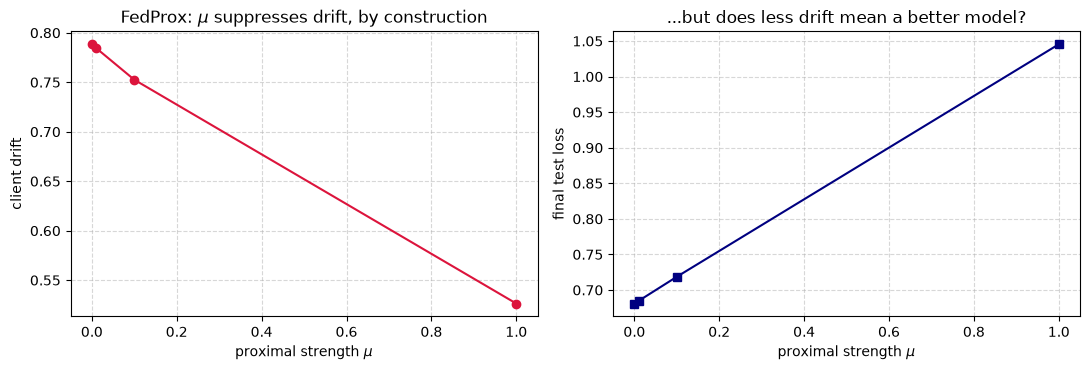

In [28]:
# --- Reference solution (instructor: blank this out for students) ---

TAU_P = 16
R_P = T_BUDGET // TAU_P
mus = [0.0, 0.01, 0.1, 1.0]

print(f"FedProx on the Dirichlet(alpha={ALPHA}) partition, tau={TAU_P}, {R_P} rounds")
print(f"{'mu':>7}  {'drift':>8}  {'test loss':>10}  {'test acc':>9}")
print("-" * 40)
prox_rows = []
for mu in mus:
    h = run_distributed(R_P, TAU_P, shards_nid, weighting="by_size", mu=mu)
    prox_rows.append((mu, h))
    print(f"{mu:>7.2f}  {h[-1]['drift']:>8.3f}  {h[-1]['loss']:>10.4f}  {h[-1]['acc']:>9.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot([r[0] for r in prox_rows], [r[1][-1]["drift"] for r in prox_rows], "o-",
           color="crimson")
ax[0].set_xlabel(r"proximal strength $\mu$"); ax[0].set_ylabel("client drift")
ax[0].set_title(r"FedProx: $\mu$ suppresses drift, by construction")
ax[0].grid(True, ls="--", alpha=0.5)

ax[1].plot([r[0] for r in prox_rows], [r[1][-1]["loss"] for r in prox_rows], "s-",
           color="navy")
ax[1].set_xlabel(r"proximal strength $\mu$"); ax[1].set_ylabel("final test loss")
ax[1].set_title("...but does less drift mean a better model?")
ax[1].grid(True, ls="--", alpha=0.5)
plt.tight_layout()

d0, dmax = prox_rows[0][1][-1]["drift"], prox_rows[-1][1][-1]["drift"]
best = min(prox_rows, key=lambda r: r[1][-1]["loss"])
print(f"\ndrift: {d0:.3f} (mu=0) -> {dmax:.3f} (mu={mus[-1]})  "
      f"-- a {100 * (1 - dmax / d0):.0f}% reduction, exactly as designed")
print(f"best test loss: {best[1][-1]['loss']:.4f} at mu = {best[0]}")
print()
print("The skeptical reading -- and the one Week 9 will develop:")
print("  Drift falls monotonically in mu. That is not a result; it is the DEFINITION of")
print("  the penalty, and it would happen even if mu did nothing useful. The question is")
print("  whether the LOSS follows, and mu -> infinity is proof that it cannot always:")
print("  an infinite proximal term pins every client at theta^(r) and NOTHING is learned.")
print("  So there is an interior optimum, it is problem-dependent, and 'reduce drift' is a")
print("  means, not an end. Never report a drift reduction as if it were an improvement.")

---

## 8. Lab 6: the $\tau$–convergence–communication trade-off

Everything above assembles into the Lab 6 deliverable. The question a systems paper has to
answer is not "does Local SGD converge?" but:

> **To reach a target quality, how many bytes must cross the wire — and what $\tau$
> minimizes that?**

That reframing is what makes it engineering. It means plotting the **Pareto frontier**:
loss against cumulative bytes, one curve per $\tau$, and reading off the cheapest
configuration that hits a target. And it means doing it **twice** — once IID (distributed
training) and once non-IID (federated learning) — because the whole thesis of this lab is
that the second world is the first world plus constraints, and the frontier should move.


In [29]:
print(f"non-IID tau sweep, Dirichlet(alpha={ALPHA}), same {T_BUDGET}-local-step budget")
print(f"{'tau':>5}  {'rounds':>7}  {'MB/worker':>10}  {'test loss':>10}  {'test acc':>9}  {'drift':>7}")
print("-" * 62)
nid_runs = {}
t0 = time.perf_counter()
for tau in taus:
    h = run_distributed(T_BUDGET // tau, tau, shards_nid, weighting="by_size")
    nid_runs[tau] = h
    print(f"{tau:>5}  {T_BUDGET // tau:>7}  {h[-1]['bytes'] / 1e6:>10.3f}  {h[-1]['loss']:>10.4f}  "
          f"{h[-1]['acc']:>9.3f}  {h[-1]['drift']:>7.3f}")
print(f"\n({time.perf_counter() - t0:.1f}s)")

best_iid = min(taus, key=lambda t: iid_runs[t][-1]["loss"])
best_nid = min(taus, key=lambda t: nid_runs[t][-1]["loss"])
print(f"best tau, IID     : {best_iid}  (loss {iid_runs[best_iid][-1]['loss']:.4f})")
print(f"best tau, non-IID : {best_nid}  (loss {nid_runs[best_nid][-1]['loss']:.4f})")
print(f"\ndrift at tau=64: IID {iid_runs[64][-1]['drift']:.3f}  ->  "
      f"non-IID {nid_runs[64][-1]['drift']:.3f}  "
      f"({nid_runs[64][-1]['drift'] / iid_runs[64][-1]['drift']:.1f}x)")

non-IID tau sweep, Dirichlet(alpha=0.5), same 256-local-step budget
  tau   rounds   MB/worker   test loss   test acc    drift
--------------------------------------------------------------


    1      256       1.321      0.8309      0.864    0.123


    2      128       0.660      0.7900      0.868    0.223


    4       64       0.330      0.7332      0.864    0.429


    8       32       0.165      0.6852      0.866    0.625


   16       16       0.083      0.6810      0.863    0.788


   32        8       0.041      0.7173      0.813    0.990


   64        4       0.021      0.7894      0.748    1.241

(31.7s)
best tau, IID     : 64  (loss 0.6568)
best tau, non-IID : 16  (loss 0.6810)

drift at tau=64: IID 0.257  ->  non-IID 1.241  (4.8x)


  tau   IID: MB to target   non-IID: MB to target
--------------------------------------------------
    1              1.2745           never reached
    2              0.6347           never reached
    4              0.3199           never reached
    8              0.1600                  0.1600
   16              0.0826                  0.0826
   32              0.0413           never reached
   64              0.0206           never reached

cheapest IID     : tau = 64  (0.0206 MB)
cheapest non-IID : tau = 16  (0.0826 MB)

non-IID, tau values that NEVER reached the target: [1, 2, 4, 32, 64]
   ^ note WHICH ones: the smallest and the largest. Not a bug -- an interior
     optimum. Small tau is starved of local progress per byte; large tau drifts
     to a worse solution and never recovers. IID has no such exclusion.

IID    : tau=64 reaches the target with 62x fewer bytes than tau=1
non-IID: tau=1 never reaches it at all


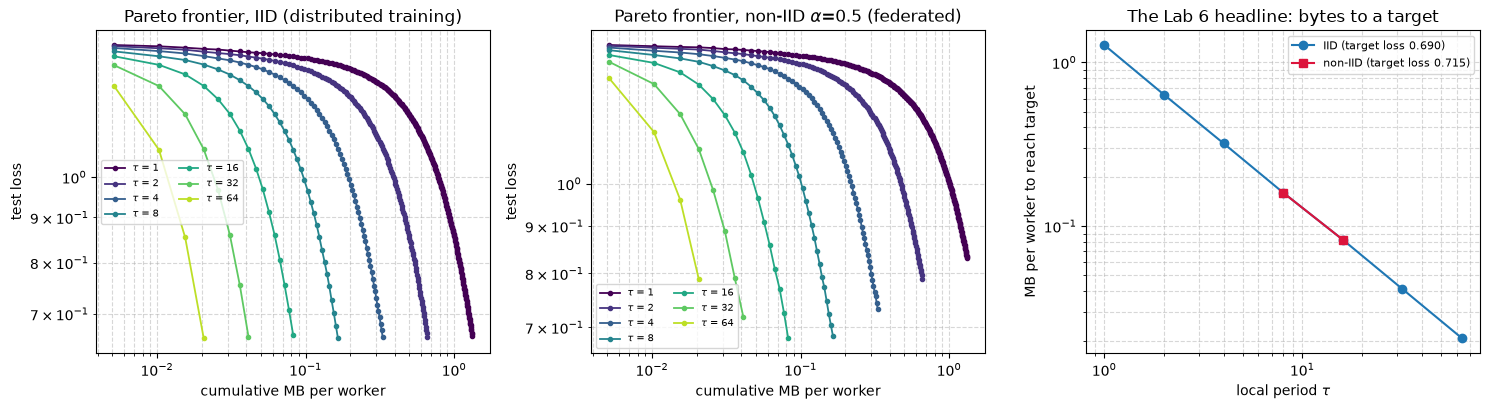

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

for c, tau in zip(colors, taus):
    ax[0].loglog([d["bytes"] / 1e6 for d in iid_runs[tau]], [d["loss"] for d in iid_runs[tau]],
                 "o-", color=c, ms=3, lw=1.3, label=f"$\\tau$ = {tau}")
ax[0].set_xlabel("cumulative MB per worker"); ax[0].set_ylabel("test loss")
ax[0].set_title("Pareto frontier, IID (distributed training)")
ax[0].legend(fontsize=7, ncol=2); ax[0].grid(True, ls="--", alpha=0.5, which="both")

for c, tau in zip(colors, taus):
    ax[1].loglog([d["bytes"] / 1e6 for d in nid_runs[tau]], [d["loss"] for d in nid_runs[tau]],
                 "o-", color=c, ms=3, lw=1.3, label=f"$\\tau$ = {tau}")
ax[1].set_xlabel("cumulative MB per worker"); ax[1].set_ylabel("test loss")
ax[1].set_title(f"Pareto frontier, non-IID $\\alpha$={ALPHA} (federated)")
ax[1].legend(fontsize=7, ncol=2); ax[1].grid(True, ls="--", alpha=0.5, which="both")

# --- bytes to reach a target loss, per tau ---
def bytes_to_target(hist, target):
    for d in hist:
        if d["loss"] <= target:
            return d["bytes"]
    return np.nan

# The target must be TIGHT enough that reaching it is an achievement -- a loose target is
# reached in round 1 by every tau, which would make this plot a tautology (bytes per round)
# dressed up as a result. Use 5% above the best loss ANY configuration achieved.
TGT_IID = min(iid_runs[t][-1]["loss"] for t in taus) * 1.05
TGT_NID = min(nid_runs[t][-1]["loss"] for t in taus) * 1.05

b_iid = [bytes_to_target(iid_runs[t], TGT_IID) / 1e6 for t in taus]
b_nid = [bytes_to_target(nid_runs[t], TGT_NID) / 1e6 for t in taus]

ax[2].loglog(taus, b_iid, "o-", label=f"IID (target loss {TGT_IID:.3f})")
ax[2].loglog(taus, b_nid, "s-", color="crimson", label=f"non-IID (target loss {TGT_NID:.3f})")
ax[2].set_xlabel(r"local period $\tau$")
ax[2].set_ylabel("MB per worker to reach target")
ax[2].set_title("The Lab 6 headline: bytes to a target")
ax[2].legend(fontsize=8); ax[2].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

print(f"{'tau':>5}  {'IID: MB to target':>18}  {'non-IID: MB to target':>22}")
print("-" * 50)
for t, bi, bn in zip(taus, b_iid, b_nid):
    si = f"{bi:.4f}" if not np.isnan(bi) else "never reached"
    sn = f"{bn:.4f}" if not np.isnan(bn) else "never reached"
    print(f"{t:>5}  {si:>18}  {sn:>22}")
ok_i = [(t, b) for t, b in zip(taus, b_iid) if not np.isnan(b)]
ok_n = [(t, b) for t, b in zip(taus, b_nid) if not np.isnan(b)]
bi_t, bi_v = min(ok_i, key=lambda x: x[1])
bn_t, bn_v = min(ok_n, key=lambda x: x[1])
print(f"\ncheapest IID     : tau = {bi_t}  ({bi_v:.4f} MB)")
print(f"cheapest non-IID : tau = {bn_t}  ({bn_v:.4f} MB)")
miss_n = [t for t, b in zip(taus, b_nid) if np.isnan(b)]
print(f"\nnon-IID, tau values that NEVER reached the target: {miss_n}")
print("   ^ note WHICH ones: the smallest and the largest. Not a bug -- an interior")
print("     optimum. Small tau is starved of local progress per byte; large tau drifts")
print("     to a worse solution and never recovers. IID has no such exclusion.")
if not np.isnan(b_iid[0]):
    print(f"\nIID    : tau={bi_t} reaches the target with {b_iid[0] / bi_v:.0f}x fewer bytes than tau=1")
print(f"non-IID: tau=1 " + ("never reaches it at all" if np.isnan(b_nid[0])
                           else f"needs {b_nid[0] / bn_v:.0f}x more bytes than tau={bn_t}"))

### The fourth state nobody agrees about: batch statistics

One loose end, and it is the one that becomes an algorithm in Week 11. We have been
averaging the BatchNorm running statistics along with the parameters, using the same
weights — but Section 1 already showed that batch statistics **do not obey the averaging
argument**. They are not parameters; they are summaries of *each client's own input
distribution*. Under non-IID data those distributions genuinely differ, so what does their
weighted mean even mean?

Three policies exist in the wild — average them (what we did), keep the server's own, or
**let each client keep its own and never upload them** (that last one is FedBN). We are
going to be careful about what we can and cannot conclude here, because there is a trap in
our own setup.

Our `eqx.nn.BatchNorm` runs with `mode="batch"`: it normalizes using the statistics of the
batch in front of it, **at evaluation time too**. So the running statistics we have been
dutifully averaging never actually influence our test loss, and comparing "average" against
"don't average" on our metric would print two identical numbers and prove nothing. That is
worth saying out loud rather than shipping a null result as a finding.

What we *can* measure honestly — and what actually motivates FedBN — is whether clients'
batch statistics **disagree**, and whether that disagreement tracks the data distribution.


In [31]:
def bn_divergence(shards, tau, label):
    # Run ONE round from a common start, then look at how far apart the clients'
    # BatchNorm statistics ended up -- relative to how far apart their PARAMETERS did.
    K = len(shards)
    wp, wb, wo = broadcast(params0, K), broadcast(bn0, K), broadcast(opt0, K)
    xs, ys = sample_batches(shards, tau, 0)
    cp, cb, co, _ = run_workers(wp, wb, wo, xs, ys, jnp.ones((K, tau)), 0.0)
    u = jnp.full((K,), 1.0 / K)
    mean_b, mean_p = aggregate(cb, u), aggregate(cp, u)
    spread = lambda tree, m: float(jnp.mean(jax.vmap(
        lambda t: global_norm(jax.tree.map(lambda a, mm: a - mm, t, m)))(tree)))
    d_bn, d_p = spread(cb, mean_b), spread(cp, mean_p)
    print(f"{label:>22}  bn-stat spread {d_bn:>7.4f}   param spread {d_p:>7.4f}   "
          f"ratio {d_bn / d_p:>5.2f}")
    return d_bn, d_p


print(f"disagreement between clients' states after ONE round of tau={TAU_C}, from a common start")
print("-" * 88)
bn_iid = bn_divergence(shards_iid, TAU_C, "IID")
bn_nid = bn_divergence(shards_nid, TAU_C, f"non-IID (a={ALPHA})")
print()
print(f"batch statistics diverge {bn_nid[0] / bn_iid[0]:.1f}x more under non-IID than under IID.")
print("So the disagreement is REAL and it tracks the data distribution -- which is exactly")
print("FedBN's premise: these are per-client properties, and averaging them may be")
print("destroying information rather than sharing it.")
print()
print("But be precise about the strength of this evidence, because it is weak:")
print("  - our synthetic clients differ in LABEL mix, not in PIXEL statistics. Real")
print("    feature skew (different cameras, lighting, demographics) is a much bigger")
print("    effect, and it is the case FedBN was actually built for.")
print("  - with mode='batch', our metric cannot score the policies at all (see above).")
print("  - FedBN cannot be scored by ONE global test loss even in principle: every client")
print("    ends up with a DIFFERENT model, so it needs per-client evaluation.")
print("\nSo: we have established that the question is real, and NOT answered it.")
print("That is Week 11's job, and it needs a harness this notebook does not have.")

disagreement between clients' states after ONE round of tau=8, from a common start
----------------------------------------------------------------------------------------
                   IID  bn-stat spread  0.0282   param spread  0.0618   ratio  0.46


       non-IID (a=0.5)  bn-stat spread  0.0965   param spread  0.5447   ratio  0.18

batch statistics diverge 3.4x more under non-IID than under IID.
So the disagreement is REAL and it tracks the data distribution -- which is exactly
FedBN's premise: these are per-client properties, and averaging them may be
destroying information rather than sharing it.

But be precise about the strength of this evidence, because it is weak:
  - our synthetic clients differ in LABEL mix, not in PIXEL statistics. Real
    feature skew (different cameras, lighting, demographics) is a much bigger
    effect, and it is the case FedBN was actually built for.
  - with mode='batch', our metric cannot score the policies at all (see above).
  - FedBN cannot be scored by ONE global test loss even in principle: every client
    ends up with a DIFFERENT model, so it needs per-client evaluation.

So: we have established that the question is real, and NOT answered it.
That is Week 11's job, and it needs a harness t

> **Observe:** the Lab 6 deliverable is the pair of frontiers, and the contrast between
> them is the whole lab in one figure.
>
> **On IID data, $\tau$ is close to free money.** Every $\tau$ reaches the target, and the
> largest reaches it with **orders of magnitude fewer bytes** than $\tau=1$. The frontier is
> essentially monotone: bigger $\tau$, same loss, fewer bytes. If you train on a cluster
> with a slow interconnect and you are not using Local SGD, you are paying a bill you do
> not owe.
>
> **On non-IID data the frontier changes shape, and grows a hole.** The $\tau$ sweep is now
> a clear **U**: the best $\tau$ is *interior*, and **both extremes fail to reach the target
> at all** at this budget. The large-$\tau$ end we can explain and have measured — drift at
> $\tau=64$ is ~5× its IID value, and that drift is **bias** (each client pulling toward its
> own optimum), not noise that averaging cleans up. **Turning $\tau$ up in FL does not just
> save bytes; it changes what you converge to.**
>
> The small-$\tau$ end we should flag rather than explain away: at a fixed local-step
> budget, $\tau=1$ lands at a clearly worse loss under non-IID than under IID, and this
> notebook has *not* isolated why. There are at least two candidate mechanisms — the
> effective-batch effect from Section 2, and the fact that our clients each sample 32
> examples per step regardless of $n_k$ while being *weighted* by $n_k$, so the pooled batch
> is stratified rather than IID from the union. Distinguishing those needs an experiment we
> have not run. Noting an unexplained feature of your own plot is not a weakness of the
> report; silently narrating a mechanism you did not test is.
>
> That is the difference between the two halves of this course, stated as a plot. Same
> algorithm, same knob, same code path — and in one world $\tau$ is a free lunch while in
> the other it is a bias/communication trade with an interior optimum you have to find
> empirically. Everything Weeks 9–11 do is an attempt to make the right-hand plot look more
> like the left-hand one.
>
> **What this CPU cannot tell you, and Lab 6's GPU half must.** Every number here is bytes
> and rounds, both hardware-independent. What is missing is **overlap**: on real hardware,
> communication can hide behind computation, so the *marginal* value of a saved AllReduce
> depends on whether it was on the critical path. That is why the deliverable is
> `loss vs bytes` — a portable claim — and why `loss vs wall-clock` is a claim you may only
> make on the GPU node, with the interconnect named.


---

## Summary

Today the course turned over. Weeks 5 and 6 distributed the *computation*; from Week 8 on,
the *data* is distributed and cannot be moved. This lab is the plank between them, and the
reason it holds is a chain of two exact reductions:

$$\text{synchronous data-parallel SGD} \;\underset{\tau=1}{=}\; \textbf{Local SGD}
\;\underset{\substack{C=1,\ n_k \text{ equal}\\ \tau_k \text{ equal},\ \text{IID}}}{=}\; \textbf{FedAvg}$$

Both links were verified in code to float32 precision. They are identities, not analogies.

- **The bill is $2\frac{P-1}{P}|g|$ bytes per worker per step, flat in $P$, capped at
  $2|g|$.** Ring AllReduce's per-worker cost does not grow with the cluster — that is what
  makes synchronous data parallelism viable, and why "AllReduce costs $O(P\,|g|)$ bytes per worker" is a folk error.
  What *does* grow with $P$ is a parameter server's traffic **at the server** ($2P|g|$) —
  and FL's architecture is a parameter server. Divided by a named bandwidth, that bill is
  free on NVLink, serious on Ethernet, and **physically impossible on a phone uplink**.
  That impossibility, not privacy, is where federated learning starts.
- **The two lazy fixes both charge you.** Large-batch training cuts AllReduces by removing
  steps, and our sweep paid for it in test loss past the critical batch size. Async removes
  the barrier and pays in **staleness**: monotone degradation at an identical gradient
  budget, because the same work applied at a stale point is worth less. Both accepted "one
  sync per step" as a law.
- **Local SGD breaks the law.** $\tau$ local steps, then average the parameters. Total bytes
  $= \frac{T}{\tau} \times 2\frac{P-1}{P}|\theta|$ — the **frequency** divides by $\tau$, the
  **volume per sync does not change** (that is Week 10's job). Stich (2018): the saving is
  free while $\tau = O(\sqrt{T/P})$, and our IID sweep confirmed it — $64\times$ fewer bytes
  for a couple of percent of loss, with drift growing like $\sqrt{\tau}$.
- **Drift is the currency $\tau$ trades in**, and its character depends entirely on the
  data. IID: workers separate by *minibatch noise* and averaging pulls them back. Non-IID:
  each client descends a *different objective* and they separate **deterministically** —
  drift becomes bias, and averaging is fighting a real disagreement. That single distinction
  is why federated learning is hard and distributed training is not.
- **FedAvg = Local SGD + four constraints**, and we measured each one: **non-IID** (~5×
  drift, and it changes drift's *character* from noise to bias), **partial participation**
  (nearly free on IID — dangerous only in *interaction* with non-IID), **unequal client
  sizes** (the weights decide *which objective* you optimize at all), and **systems
  heterogeneity** (running longer buys a louder vote — objective inconsistency, which a
  matched-compute control row was needed to separate from simply doing less work).
  Together they compound badly — roughly halving accuracy at the same $\tau$.
- **Engineering discipline.** `scan` over $\tau$ kept compile time flat across a $32\times$
  sweep (Week 4's promise, collected — while its run-time cost on XLA:CPU was reported, not
  hidden). `vmap` over workers made the client axis a transformation. The four states stayed
  separate, and the awkward one — **batch statistics** — is the one that does not obey the
  averaging argument at all. That loose end is FedBN, Week 11.
- **The deliverable is `loss vs bytes`, not `loss vs seconds`**, because bytes are exact on
  any machine and this laptop's seconds are exact on none.

**The thread from here.** You now know FedAvg — you derived it, implemented it, and proved
it equals an algorithm you already had. Week 8 gives it its real setting (cross-device vs
cross-silo, the JAX–Flower glue) and Week 9 runs it at 100 clients under Flower — that is
**Stage 4**, and it is a *port*, not a rewrite: `run_distributed` already has every knob.
Then the rest of the course is, precisely, the four constraints being attacked one at a
time: drift (Week 9: FedProx, SCAFFOLD), bytes and participation (Week 10: the $|\theta|$
factor Local SGD never touched), non-IID and personalization (Week 11), and then the
question this lab quietly assumed away — **is $\theta_k$ safe to send?** (Weeks 12–13: no).

### Reading

- **Course textbook, Ch. 4 (Gradient Methods)** — *Federated Learning: From Theory to
  Practice* ([arXiv:2505.19183](https://arxiv.org/abs/2505.19183)). Read it *after* this
  notebook, not before: you have now derived the update rule Ch. 4 analyses, so read it as
  the convergence theory for something you already built. This is where the textbook joins
  the course — Part I–II ran on PPT and the JAX docs because no FL textbook covers XLA.
- **Stich (2018), "Local SGD Converges Fast and Communicates Little"**
  ([arXiv:1805.09767](https://arxiv.org/abs/1805.09767)) — the $\tau = O(\sqrt{T/P})$ result
  Section 5 tried (and, honestly, failed) to observe the knee of.
- **McMahan et al. (2017), "Communication-Efficient Learning of Deep Networks from
  Decentralized Data"** ([arXiv:1602.05629](https://arxiv.org/abs/1602.05629)) — FedAvg.
  Read Algorithm 1 against Section 6's derivation and confirm the four knobs for yourself.
- Optional, and each one is a Week 9–13 preview whose problem you have now *measured*:
  Wang et al. (2020) **FedNova** (objective inconsistency, Exercise 3), Li et al. (2020)
  **FedProx** (Exercise 4), Reddi et al. (2021) **FedOpt/FedAdam** (the $\Delta$ form).

### Further Exercises

1. **Find the knee on real hardware.** Rerun the $\tau$ sweep on the GPU node with real
   CIFAR-10 (via Grain) and the full Stage-2 ResNet. Plot loss against *wall-clock* as well
   as bytes, with the interconnect named. Where the curves disagree is exactly the
   **overlap** this CPU cannot show you — quantify it.
2. **Verify Stich's threshold.** The theory says the free regime is $\tau = O(\sqrt{T/P})$,
   so the optimal $\tau$ should **grow with $T$** and **shrink with $P$**. Sweep $T \in
   \{128, 512, 2048\}$ and $P \in \{2, 4, 8, 16\}$, find the largest $\tau$ that stays within
   1% of $\tau=1$'s loss, and plot it against $\sqrt{T/P}$. Does the exponent hold?
3. **Compose Local SGD with compression.** Local SGD divides the *frequency*; Week 10
   divides the *volume*. Quantize the averaged update to int8 (a $4\times$ volume cut) and
   sweep $\tau$ again. Do the savings multiply to $4\tau$, or does compression error
   interact with drift? Plot the 2-D frontier over $(\tau, \text{bits})$.
4. **Momentum across the round.** We used plain SGD so the $\tau=1$ reduction would be
   exact. Switch the local optimizer to `optax.sgd(momentum=0.9)` and implement three
   policies for the optimizer state at aggregation: average it, reset it each round, or keep
   it local and never upload. Which wins, and does $\tau=1$ still reduce exactly to
   synchronous SGD? (This is the seed of FedOpt/FedAdam.)
5. **Explain the small-$\tau$ end of the non-IID U.** Section 8 found that $\tau=1$ does
   clearly worse under non-IID than under IID at the same local-step budget, and did *not*
   isolate the cause. Design the experiment. Two candidates: (a) the effective-batch effect
   (Section 2) — test by re-running the IID sweep at $B=8$ so $\tau=1$'s effective batch is
   32 rather than 128; (b) a sampling/weighting mismatch — each client draws $B$ examples
   per step regardless of $n_k$ but is *weighted* by $n_k$, so the pooled batch is stratified
   by client rather than IID from the union. Test (b) by making each client's batch size
   proportional to $n_k$, which makes $\tau=1$ exactly reproduce pooled-data SGD. Which
   mechanism is it — or is it both?
6. **The straggler-vs-drift trade.** Section 3 measured staleness; Section 7 measured
   heterogeneous $\tau_k$. Real FL has both. Simulate client compute times as
   $\text{LogNormal}$, set a round deadline, and let clients that miss it contribute
   whatever partial work they finished. Sweep the deadline: too tight and you drop the slow
   clients (biasing the objective toward the fast ones — *whose data is that?*); too loose
   and every round waits. Where is the optimum, and what does it cost in fairness?
